# 04 — Neural Network Classification with Biological Data

### Predicting where a yeast protein lives in the cell

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 04 of 12  
**Level:** Intermediate  
**Primary tools:** Python, NumPy, pandas, Matplotlib, Keras 3  
**Dataset:** UCI *Yeast* — protein localization (1,484 proteins, 8 features, 10 classes)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Formulate multiclass classification as the estimation of a conditional probability distribution $P(y = k \mid x)$.
2. Derive the **softmax** function, its invariance to shifts, its Jacobian, and its numerically stable implementation.
3. Derive **categorical cross-entropy** from maximum likelihood and relate it to entropy and KL divergence.
4. Derive the gradient $\partial L / \partial z = p - y$ and verify a full backpropagation implementation with a **numerical gradient check**.
5. Use **one-hot encoding** and explain how it relates to integer labels and sparse loss functions.
6. Design, train, and diagnose a multilayer perceptron (MLP) for a real, imbalanced biological dataset.
7. Compute and interpret the **confusion matrix**, precision, recall, F1-score (macro, micro, weighted), balanced accuracy, and the Matthews correlation coefficient — from scratch.
8. Use **class weights** to address class imbalance and explain the mathematical effect on the loss and gradients.
9. Quantify uncertainty in a test result with a **bootstrap confidence interval**, and state the limits of what the result shows.

> **What is new compared with Notebook 03?** This is the first notebook with a *real* biological dataset. The mathematics is also deeper: we derive the quantities that Keras computes for us, then verify them numerically against both NumPy and Keras.

## 1. The biological problem and the learning task

A eukaryotic cell is divided into compartments. A protein can only do its job in the right place: a DNA-binding protein belongs in the **nucleus**, an enzyme of the respiratory chain in the **mitochondrion**, a secreted protein must leave the cell. Cells route proteins using signals encoded in the amino-acid sequence, such as N-terminal signal sequences, nuclear localization signals, or a C-terminal retention signal. Predicting the **subcellular localization** of a protein from sequence-derived information is therefore a classic bioinformatics task, useful for annotating newly sequenced genomes and for interpreting protein function.

The *Yeast* dataset (Kenta Nakai, UCI Machine Learning Repository) contains **1,484 yeast proteins**. For each protein, eight numerical features summarize sequence-based signals, and the label gives one of **ten localization sites**.

### 1.1 Formal task

Each protein is a feature vector $x \in \mathbb{R}^{F}$ with $F = 8$. Its label is one of $K = 10$ classes. We want a model that outputs a probability for every class:

$$
\hat{p}(x) = \big(\hat{p}_1(x), \dots, \hat{p}_K(x)\big), \qquad \hat{p}_k(x) \approx P(y = k \mid x), \qquad \sum_{k=1}^{K} \hat{p}_k(x) = 1 .
$$

The predicted class is $\hat{y} = \arg\max_k \hat{p}_k(x)$.

### 1.2 Why this dataset is instructive

- It is **small** (CPU-friendly) but **real**: classes overlap and the problem is not trivially solvable.
- The classes are **strongly imbalanced** (the largest class is roughly 90 times larger than the smallest). Accuracy alone can look good while rare classes are ignored.
- The ten classes are not equally "far" from each other biologically (three of them are membrane-protein variants), which makes error analysis interesting.

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend, plus **pandas** for tabular handling. The backend must be selected before importing Keras.

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys
import json
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

ARTIFACT_DIR = "artifacts_04"      # models and metadata
FIG_DIR = "figures_04"             # exported figures (useful for a README or slides)
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__)
print("pandas :", pd.__version__)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6
pandas : 2.3.3


## 3. Class definitions and a consistent visual style

Good figures make the analysis easier to read, so we define a visual style once and reuse it. Each of the ten localization classes gets **one fixed colour** that is used in every figure of this notebook.

The ten classes, ordered from the most to the least frequent, are:

| Code | Localization site |
|---|---|
| `CYT` | Cytoplasm (cytosolic and cytoskeletal) |
| `NUC` | Nucleus |
| `MIT` | Mitochondria |
| `ME3` | Membrane protein, no N-terminal signal |
| `ME2` | Membrane protein, uncleaved signal |
| `ME1` | Membrane protein, cleaved signal |
| `EXC` | Extracellular |
| `VAC` | Vacuole |
| `POX` | Peroxisome |
| `ERL` | Endoplasmic reticulum lumen |

In [2]:
CLASS_ORDER = ["CYT", "NUC", "MIT", "ME3", "ME2", "ME1", "EXC", "VAC", "POX", "ERL"]
CLASS_DESCRIPTIONS = {
    "CYT": "Cytoplasm", "NUC": "Nucleus", "MIT": "Mitochondria",
    "ME3": "Membrane, no N-terminal signal", "ME2": "Membrane, uncleaved signal",
    "ME1": "Membrane, cleaved signal", "EXC": "Extracellular", "VAC": "Vacuole",
    "POX": "Peroxisome", "ERL": "ER lumen",
}
FEATURES = ["mcg", "gvh", "alm", "mit", "erl", "pox", "vac", "nuc"]
N_CLASSES = len(CLASS_ORDER)
class_to_index = {code: i for i, code in enumerate(CLASS_ORDER)}

# ---- Visual style ---------------------------------------------------------
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB"}
CLASS_COLORS = {code: plt.cm.tab10(i) for i, code in enumerate(CLASS_ORDER)}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linestyle": "-", "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.labelcolor": COLORS["dark"],
    "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0):
    """Tidy the layout, optionally export the figure, and show it."""
    fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()

## 4. The dataset

The file `yeast.data` contains one protein per row: a sequence (accession) name, eight numerical features, and the localization label.

| Feature | Meaning |
|---|---|
| `mcg` | McGeoch's method for signal-sequence recognition |
| `gvh` | von Heijne's method for signal-sequence recognition |
| `alm` | Score of the ALOM membrane-spanning-region prediction program |
| `mit` | Discriminant-analysis score of the amino-acid content of the N-terminal region (mitochondrial vs. non-mitochondrial) |
| `erl` | Presence of an "HDEL" substring (a signal for retention in the endoplasmic reticulum lumen) |
| `pox` | Peroxisomal targeting signal in the C-terminus |
| `vac` | Discriminant-analysis score of the amino-acid content of vacuolar and extracellular proteins |
| `nuc` | Discriminant-analysis score of nuclear localization signals |

The features are **precomputed scores**, not raw sequences. The dataset is distributed under a Creative Commons Attribution 4.0 licence (see the references at the end for the citation).

The cell below downloads the file once into a local `data/` folder. If your computer has no internet access, download `yeast.data` manually from the UCI page and place it in `data/`.

In [3]:
DATA_DIR = "data"
DATA_PATH = os.path.join(DATA_DIR, "yeast.data")
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/yeast/yeast.data"
COLUMNS = ["sequence_name"] + FEATURES + ["localization_site"]

def load_yeast(path=DATA_PATH, url=DATA_URL):
    """Read the Yeast dataset, downloading it first if it is not available locally."""
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print("Downloading:", url)
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as error:
            raise RuntimeError(
                f"Could not download the dataset ({error}). Download 'yeast.data' manually from "
                f"https://archive.ics.uci.edu/dataset/110/yeast and save it as '{path}'."
            ) from error
    return pd.read_csv(path, sep=r"\s+", header=None, names=COLUMNS)

df = load_yeast()
display(df.head())

Downloading: https://archive.ics.uci.edu/ml/machine-learning-databases/yeast/yeast.data


,sequence_name,mcg,gvh,alm,mit,erl,pox,vac,nuc,localization_site
0,ADT1_YEAST,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,ADT2_YEAST,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,ADT3_YEAST,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,AAR2_YEAST,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,AATM_YEAST,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT


In [4]:
# Sanity checks before any modelling: shape, types, missing values, label set.
assert df.shape == (1484, 10), f"Unexpected shape: {df.shape}"
assert set(df["localization_site"]) == set(CLASS_ORDER), "Unexpected class labels"

print("Shape               :", df.shape)
print("Missing values      :", int(df.isna().sum().sum()))
print("Feature dtypes      :", sorted(set(df[FEATURES].dtypes.astype(str))))
print("Duplicated names    :", int(df["sequence_name"].duplicated().sum()))
print("Duplicated feature rows:", int(df[FEATURES].duplicated().sum()))

summary = pd.DataFrame({
    "min": df[FEATURES].min(), "mean": df[FEATURES].mean(),
    "max": df[FEATURES].max(), "distinct values": df[FEATURES].nunique(),
}).round(3)
display(summary)

Shape               : (1484, 10)
Missing values      : 0
Feature dtypes      : ['float64']
Duplicated names    : 22
Duplicated feature rows: 31


,min,mean,max,distinct values
mcg,0.11,0.500,1.00,81
gvh,0.13,0.500,1.00,79
alm,0.21,0.500,1.00,53
mit,0.00,0.261,1.00,78
erl,0.50,0.505,1.00,2
pox,0.00,0.008,0.83,3
vac,0.00,0.500,0.73,48
nuc,0.00,0.276,1.00,68


Two points deserve attention:

- All features already lie in $[0, 1]$, but their **distributions differ** (for example, `erl` takes very few distinct values because it indicates the presence of a signal). We will still standardize them inside the model; the effect is explored in an exercise.
- Some **feature rows are duplicated**. If identical feature vectors with the same label end up in both the training and the test partitions, test performance is slightly inflated. This is a mild form of leakage that we note as a limitation (Section 19).

In [5]:
# Convert to NumPy arrays: features (float32), integer labels (int32), and protein names.
X = df[FEATURES].to_numpy(dtype="float32")
y = df["localization_site"].map(class_to_index).to_numpy(dtype="int32")
protein_names = df["sequence_name"].to_numpy()

counts = pd.Series(np.bincount(y, minlength=N_CLASSES), index=CLASS_ORDER, name="count")
class_table = pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(1),
                            "site": pd.Series(CLASS_DESCRIPTIONS)})
display(class_table)
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.0f} : 1")

,count,percent,site
CYT,463,31.2,Cytoplasm
NUC,429,28.9,Nucleus
MIT,244,16.4,Mitochondria
ME3,163,11.0,"Membrane, no N-terminal signal"
ME2,51,3.4,"Membrane, uncleaved signal"
ME1,44,3.0,"Membrane, cleaved signal"
EXC,35,2.4,Extracellular
VAC,30,2.0,Vacuole
POX,20,1.3,Peroxisome
ERL,5,0.3,ER lumen


Imbalance ratio (largest / smallest class): 93 : 1


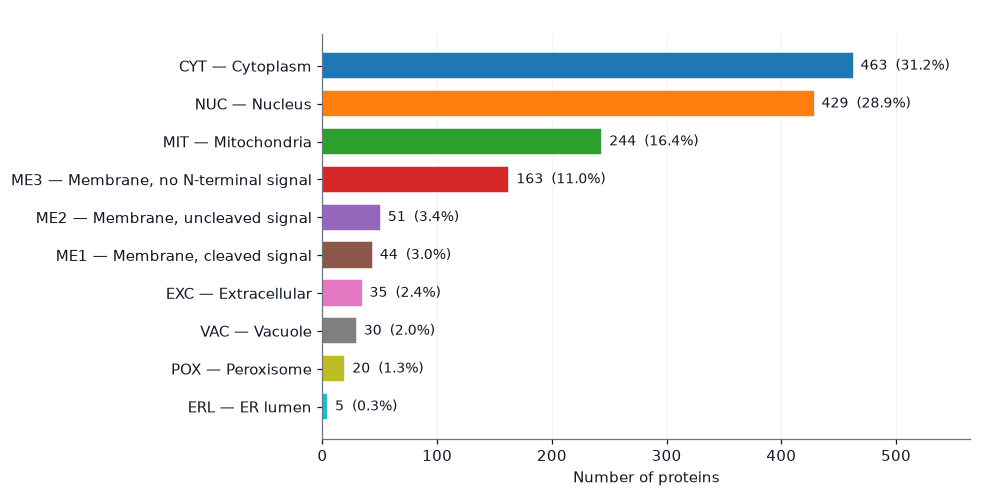

In [6]:
# Figure: class distribution.
fig, ax = plt.subplots(figsize=(9, 4.6))
ypos = np.arange(N_CLASSES)[::-1]
bars = ax.barh(ypos, counts.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER], edgecolor="white", height=0.72)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{c} — {CLASS_DESCRIPTIONS[c]}" for c in CLASS_ORDER])
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_width() + 6, bar.get_y() + bar.get_height() / 2,
            f"{count}  ({100 * count / counts.sum():.1f}%)", va="center", fontsize=9, color=COLORS["dark"])
ax.set_xlim(0, counts.max() * 1.22)
ax.set_xlabel("Number of proteins")
ax.set_title("Yeast dataset: the classes are strongly imbalanced")
ax.grid(axis="y", visible=False)
finish(fig, "01_class_distribution")

## 5. Stratified train / validation / test split

We split **before** looking at the data in detail or fitting any preprocessing. Because some classes are tiny (the smallest has only 5 proteins), the split function guarantees that **every class appears in every partition** and keeps class proportions approximately constant.

For a class with $n_k$ proteins, we assign $\max(1, \operatorname{round}(0.15\, n_k))$ to validation, $\max(1, \operatorname{round}(0.15\, n_k))$ to test, and the rest to training.

In [7]:
def stratified_split_indices(labels, val_fraction=0.15, test_fraction=0.15, seed=SEED):
    """Return train/validation/test indices; every class appears in every partition."""
    split_rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for class_id in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == class_id))
        n_val = max(1, int(round(val_fraction * len(idx))))
        n_test = max(1, int(round(test_fraction * len(idx))))
        val_idx.append(idx[:n_val])
        test_idx.append(idx[n_val:n_val + n_test])
        train_idx.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(part)) for part in (train_idx, val_idx, test_idx)]

train_idx, val_idx, test_idx = stratified_split_indices(y)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
names_test = protein_names[test_idx]

# The partitions must be disjoint and cover every protein exactly once.
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(y)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(y)

partition_counts = pd.DataFrame({
    "train": np.bincount(y_train, minlength=N_CLASSES),
    "validation": np.bincount(y_val, minlength=N_CLASSES),
    "test": np.bincount(y_test, minlength=N_CLASSES),
}, index=CLASS_ORDER)
partition_counts["total"] = partition_counts.sum(axis=1)
display(partition_counts)
print(f"Sizes -> train: {len(y_train)}, validation: {len(y_val)}, test: {len(y_test)}")

,train,validation,test,total
CYT,325,69,69,463
NUC,301,64,64,429
MIT,170,37,37,244
ME3,115,24,24,163
ME2,35,8,8,51
ME1,30,7,7,44
EXC,25,5,5,35
VAC,22,4,4,30
POX,14,3,3,20
ERL,3,1,1,5


Sizes -> train: 1040, validation: 222, test: 222


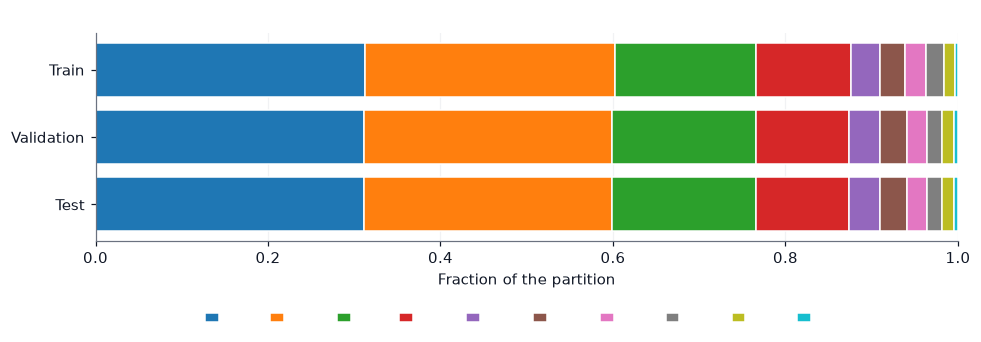

In [8]:
# Figure: class composition of the three partitions (proportions), so the stratification is visible.
fig, ax = plt.subplots(figsize=(9, 3.4))
fractions = partition_counts[["train", "validation", "test"]] / partition_counts[["train", "validation", "test"]].sum()
left = np.zeros(3)
for code_name in CLASS_ORDER:
    values = fractions.loc[code_name].values
    ax.barh(["Train", "Validation", "Test"], values, left=left, color=CLASS_COLORS[code_name],
            edgecolor="white", label=code_name)
    left += values
ax.set_xlim(0, 1); ax.invert_yaxis()
ax.set_xlabel("Fraction of the partition")
ax.set_title("Stratification keeps class proportions similar across partitions")
ax.legend(ncol=10, loc="upper center", bbox_to_anchor=(0.5, -0.28), columnspacing=0.9, handlelength=1.0)
ax.grid(axis="y", visible=False)
finish(fig, "02_partition_composition")

**Warning about rare classes.** The smallest class (`ERL`) has only 5 proteins: roughly 3 for training, 1 for validation, and 1 for testing. A metric for this class computed on one test protein is either 0 or 1 — it is an anecdote, not an estimate. We will keep this in mind when interpreting results. A more reliable evaluation of rare classes requires cross-validation (Notebook 07).

## 6. Exploratory data analysis (training set only)

Exploration also uses information from the data. To keep the validation and test sets truly unseen, **we explore the training partition only**. Whatever we learn here (for example, which features seem informative) must not be derived from the other partitions.

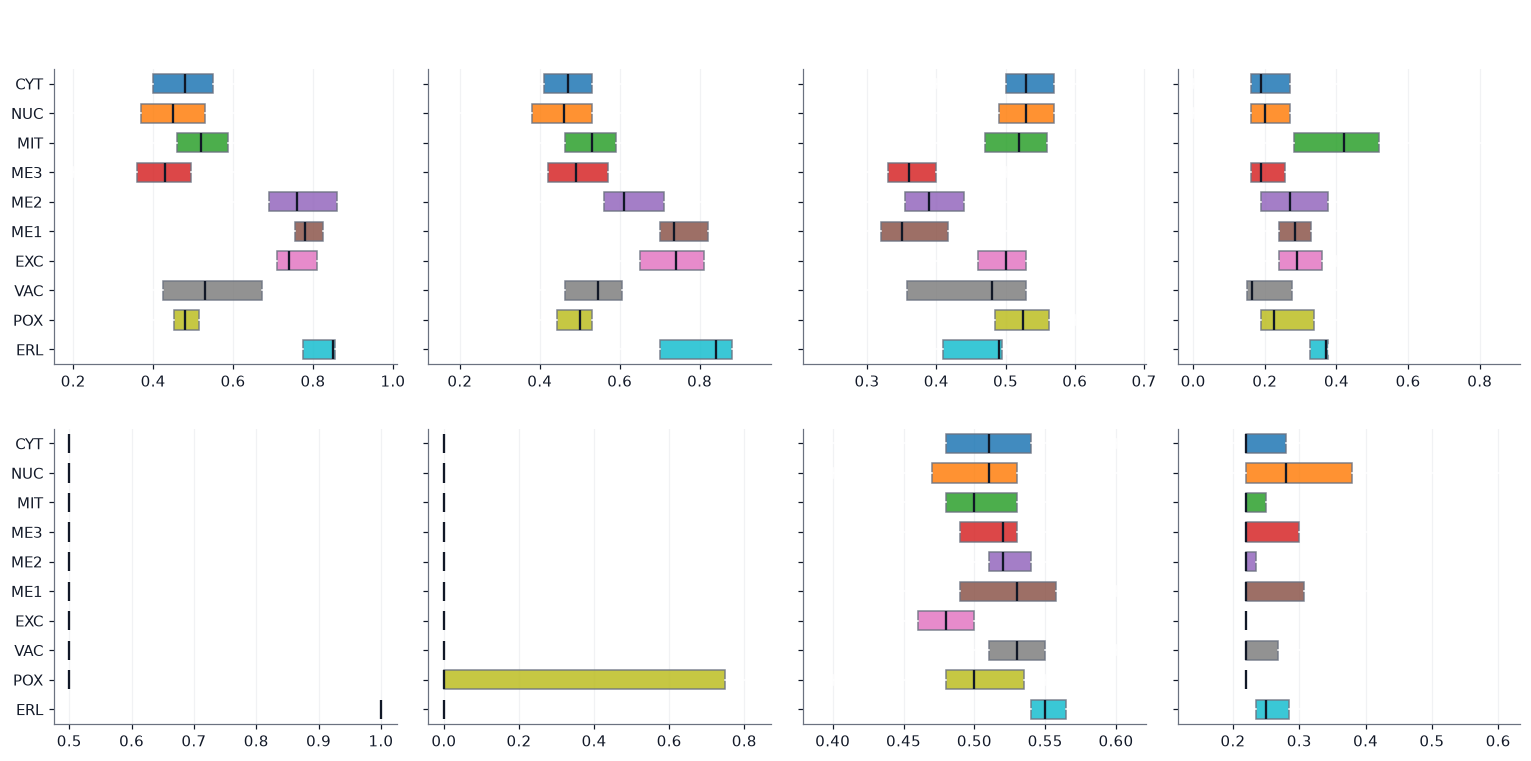

In [9]:
# Figure: distribution of every feature within every class (training data).
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharey=True)
for j, (ax, feature) in enumerate(zip(axes.ravel(), FEATURES)):
    data = [X_train[y_train == k, j] for k in range(N_CLASSES)]
    box_style = dict(patch_artist=True, showfliers=False, widths=0.65,
                     medianprops={"color": COLORS["dark"], "linewidth": 1.5})
    try:
        bp = ax.boxplot(data, orientation="horizontal", **box_style)   # Matplotlib >= 3.10
    except TypeError:
        bp = ax.boxplot(data, vert=False, **box_style)                  # older Matplotlib
    for patch, code_name in zip(bp["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[code_name]); patch.set_alpha(0.85); patch.set_edgecolor(COLORS["gray"])
    ax.set_title(feature)
    ax.set_yticks(range(1, N_CLASSES + 1)); ax.set_yticklabels(CLASS_ORDER)
    ax.grid(axis="y", visible=False)
axes[0, 0].invert_yaxis()
fig.suptitle("Feature distributions by localization class (training set)", fontsize=13, fontweight="bold", x=0.01, ha="left")
finish(fig, "03_feature_distributions_by_class")

How to read the figure (check these points against what you see):

- A feature whose boxes sit at clearly different positions for different classes carries class information. Features whose boxes overlap almost completely are less useful on their own.
- Look at `erl` and `pox`. They are signal indicators, so they may be nearly constant in most classes and differ mainly for the rare classes `ERL` and `POX`. A feature can be extremely useful for a small class and nearly invisible in global statistics.
- Boxes of the large classes (`CYT`, `NUC`, `MIT`, `ME3`) overlap on most features, so we should not expect perfect classification.

### 6.1 Correlation between features

The Pearson correlation between features $i$ and $j$ is

$$
r_{ij} = \frac{\operatorname{Cov}(x_i, x_j)}{\sigma_i \, \sigma_j} \in [-1, 1] .
$$

Strongly correlated features carry redundant information; neural networks tolerate this, but it influences how we interpret the model.

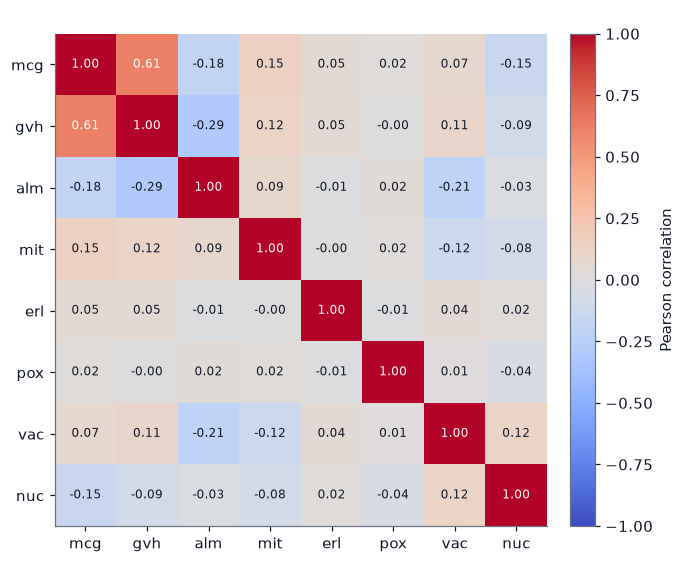

In [10]:
corr = np.corrcoef(X_train, rowvar=False)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
ax.grid(False)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr[i, j]) > 0.6 else COLORS["dark"])
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title("Feature correlations (training set)")
finish(fig, "04_feature_correlations")

### 6.2 A two-dimensional view with PCA

**Principal component analysis (PCA)** finds orthogonal directions of maximal variance. For a standardized and centered matrix $X_s \in \mathbb{R}^{N \times F}$, the singular value decomposition

$$
X_s = U \Sigma V^{\top}
$$

gives the principal directions (columns of $V$). The coordinates of the samples along the first two directions are $X_s V_{[:, :2]}$, and the fraction of variance explained by component $m$ is

$$
\frac{\sigma_m^2}{\sum_{l} \sigma_l^2} .
$$

PCA is **unsupervised**; we use it here only for visualization and we fit it on training data only. It is not part of the model.

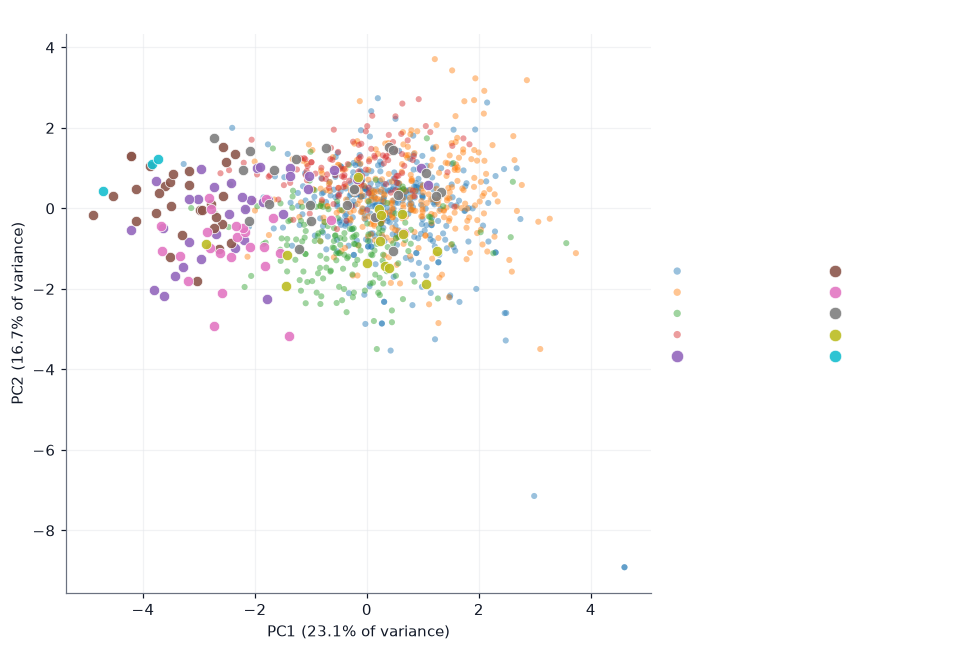

Variance explained by all components: [0.231 0.167 0.127 0.125 0.115 0.097 0.092 0.047]


In [11]:
mean_tr, std_tr = X_train.mean(axis=0), X_train.std(axis=0)
X_std = (X_train - mean_tr) / np.where(std_tr == 0, 1.0, std_tr)

U, S, Vt = np.linalg.svd(X_std, full_matrices=False)
scores = X_std @ Vt[:2].T
explained = S**2 / np.sum(S**2)

fig, ax = plt.subplots(figsize=(8.8, 6))
# Draw large classes first, rare classes last and bigger, so they stay visible.
for k, code_name in enumerate(CLASS_ORDER):
    mask = y_train == k
    rare = counts[code_name] < 100
    ax.scatter(scores[mask, 0], scores[mask, 1], s=46 if rare else 16, alpha=0.9 if rare else 0.45,
               color=CLASS_COLORS[code_name], edgecolor="white" if rare else "none", linewidth=0.5,
               label=f"{code_name} (n={mask.sum()})", zorder=3 if rare else 2)
ax.set_xlabel(f"PC1 ({100 * explained[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({100 * explained[1]:.1f}% of variance)")
ax.set_title("Training proteins projected onto the first two principal components")
ax.legend(ncol=2, loc="center left", bbox_to_anchor=(1.0, 0.5), markerscale=1.2)
finish(fig, "05_pca_projection")
print("Variance explained by all components:", np.round(explained, 3))

The classes overlap substantially in the two-dimensional projection. This does not mean a classifier will fail (it can use all eight dimensions and nonlinear combinations), but it warns us that the task is genuinely hard and that confusion between neighbouring classes is expected.

## 7. Mathematics I: from scores to probabilities (softmax)

The last layer of our network produces $K$ real numbers $z = (z_1, \dots, z_K)$ called **logits** (raw scores). We need to convert them into a probability distribution.

### 7.1 Definition

$$
p_k = \operatorname{softmax}(z)_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad k = 1, \dots, K .
$$

Properties:

- $p_k > 0$ for every $k$ and $\sum_k p_k = 1$, so $p$ is a valid probability distribution.
- Ordering is preserved: $z_i > z_j \iff p_i > p_j$. The predicted class is the same whether we take $\arg\max z$ or $\arg\max p$.
- The exponential makes large scores dominate: increasing $z_k$ by 1 multiplies its unnormalized weight by $e \approx 2.718$.

### 7.2 Shift invariance and numerical stability

Adding the same constant $c$ to every logit does not change the output:

$$
\operatorname{softmax}(z + c\mathbf{1})_k
= \frac{e^{z_k + c}}{\sum_j e^{z_j + c}}
= \frac{e^{c}\, e^{z_k}}{e^{c} \sum_j e^{z_j}}
= \operatorname{softmax}(z)_k .
$$

This is used in practice: subtracting $\max_j z_j$ before exponentiating avoids overflow, because all exponents become $\leq 0$. The **log-sum-exp** form is the stable way to compute $\ln \sum_j e^{z_j}$:

$$
\operatorname{LSE}(z) = m + \ln \sum_{j} e^{z_j - m}, \qquad m = \max_j z_j .
$$

### 7.3 Temperature

Dividing the logits by a temperature $T > 0$ gives $\operatorname{softmax}(z / T)$. A **low** temperature makes the distribution sharper (more confident), a **high** temperature makes it flatter. The limit $T \to \infty$ is the uniform distribution.

### 7.4 Special case: two classes

For $K = 2$,

$$
p_1 = \frac{e^{z_1}}{e^{z_1} + e^{z_2}} = \frac{1}{1 + e^{-(z_1 - z_2)}} = \sigma(z_1 - z_2),
$$

so softmax with two classes is the sigmoid applied to the score *difference*. Binary classification with a sigmoid is therefore a special case of the multiclass framework.

In [12]:
def softmax_np(z):
    """Numerically stable softmax along the last axis."""
    z = np.asarray(z, dtype=float)
    shifted = z - z.max(axis=-1, keepdims=True)
    e = np.exp(shifted)
    return e / e.sum(axis=-1, keepdims=True)

z = np.array([2.0, 1.0, 0.1])
p = softmax_np(z)
print("softmax([2.0, 1.0, 0.1]) =", np.round(p, 4), "| sum =", p.sum().round(6))

# Property 1: shift invariance.
print("Shift-invariant      :", np.allclose(softmax_np(z), softmax_np(z + 123.4)))

# Property 2: why stabilization matters.
big = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(big) / np.exp(big).sum()
print("Naive softmax(1000..):", naive, " <- overflow")
print("Stable softmax(1000..):", np.round(softmax_np(big), 4))

# Property 3: for K = 2, softmax equals a sigmoid of the score difference.
z2 = np.array([1.3, -0.4])
sigmoid = lambda t: 1.0 / (1.0 + np.exp(-t))
print("K=2 equals sigmoid(z1 - z2):", np.isclose(softmax_np(z2)[0], sigmoid(z2[0] - z2[1])))

softmax([2.0, 1.0, 0.1]) = [0.659  0.2424 0.0986] | sum = 1.0
Shift-invariant      : True
Naive softmax(1000..): [nan nan nan]  <- overflow
Stable softmax(1000..): [0.09   0.2447 0.6652]
K=2 equals sigmoid(z1 - z2): True


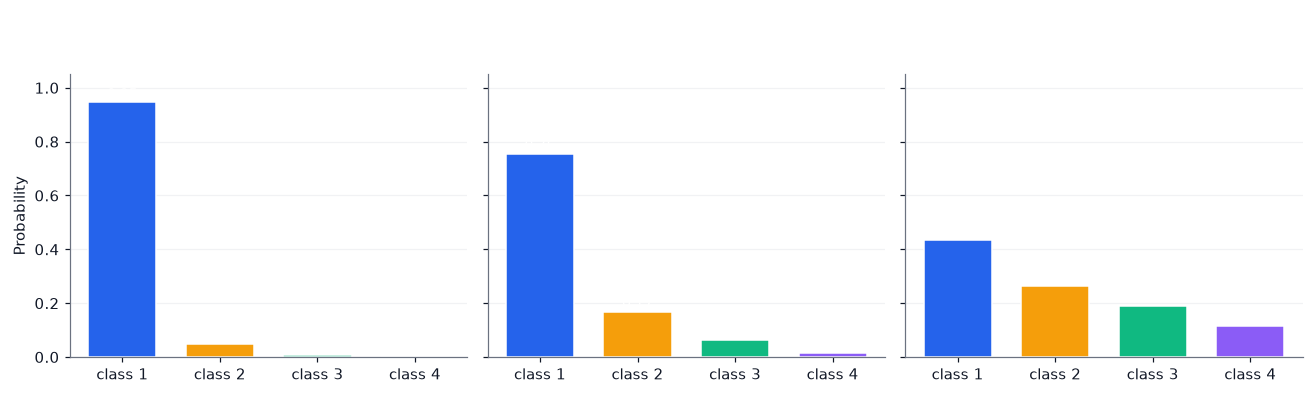

In [13]:
# Figure: the effect of temperature on the same logits.
logits = np.array([3.0, 1.5, 0.5, -1.0])
labels4 = ["class 1", "class 2", "class 3", "class 4"]
temperatures = [0.5, 1.0, 3.0]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, T in zip(axes, temperatures):
    probs = softmax_np(logits / T)
    bars = ax.bar(labels4, probs, color=[COLORS["blue"], COLORS["orange"], COLORS["green"], COLORS["purple"]],
                  edgecolor="white", width=0.7)
    for bar, value in zip(bars, probs):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.2f}", ha="center", fontsize=9)
    ax.set_title(f"T = {T}")
    ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Probability")
fig.suptitle("Softmax of the logits [3.0, 1.5, 0.5, -1.0] at three temperatures", fontsize=12, fontweight="bold", x=0.01, ha="left")
finish(fig, "06_softmax_temperature")

### 7.5 The Jacobian of softmax

Because every output depends on every logit, the derivative is a matrix. Starting from $\ln p_i = z_i - \operatorname{LSE}(z)$ and $\partial \operatorname{LSE}/\partial z_j = p_j$:

$$
\frac{\partial \ln p_i}{\partial z_j} = \delta_{ij} - p_j
\quad\Longrightarrow\quad
\frac{\partial p_i}{\partial z_j} = p_i\,(\delta_{ij} - p_j),
$$

where $\delta_{ij}$ is 1 if $i = j$ and 0 otherwise. In matrix form,

$$
J = \operatorname{diag}(p) - p\,p^{\top}.
$$

Each row of $J$ sums to zero, which is the differential version of shift invariance (the Jacobian has rank $K - 1$). We verify the formula numerically with central finite differences:

$$
\frac{\partial f}{\partial z_j} \approx \frac{f(z + \varepsilon e_j) - f(z - \varepsilon e_j)}{2\varepsilon} .
$$

In [14]:
def softmax_jacobian(z):
    p = softmax_np(z)
    return np.diag(p) - np.outer(p, p)

z = np.array([0.7, -1.2, 2.0, 0.3])
J_analytic = softmax_jacobian(z)

eps = 1e-6
J_numeric = np.zeros((len(z), len(z)))
for j in range(len(z)):
    step = np.zeros(len(z)); step[j] = eps
    J_numeric[:, j] = (softmax_np(z + step) - softmax_np(z - step)) / (2 * eps)

print("Maximum absolute difference:", np.abs(J_analytic - J_numeric).max())
print("Row sums of J (should be ~0):", np.round(J_analytic.sum(axis=1), 10))
assert np.allclose(J_analytic, J_numeric, atol=1e-7)

Maximum absolute difference: 3.6775527068044767e-11
Row sums of J (should be ~0): [-0. -0.  0.  0.]


## 8. Mathematics II: categorical cross-entropy

### 8.1 Definition for one sample

Let the true class of a sample be $c$, encoded as the one-hot vector $y$ ($y_c = 1$, all other entries 0), and let $p$ be the predicted distribution. The **categorical cross-entropy** is

$$
\ell(y, p) = -\sum_{k=1}^{K} y_k \ln p_k = -\ln p_c .
$$

Only the probability assigned to the **true class** matters. The loss is 0 if $p_c = 1$ and grows without bound as $p_c \to 0$.

For a dataset of $N$ samples:

$$
L = \frac{1}{N} \sum_{i=1}^{N} \ell(y^{(i)}, p^{(i)}) = -\frac{1}{N} \sum_{i=1}^{N} \ln p^{(i)}_{c_i} .
$$

### 8.2 Why this loss? Maximum likelihood

Assume the model defines a categorical distribution for each input. The probability it assigns to the observed label $c_i$ is $p^{(i)}_{c_i}$. For independent samples the likelihood of the whole dataset is

$$
\mathcal{L}(\theta) = \prod_{i=1}^{N} p^{(i)}_{c_i}(\theta),
\qquad
-\frac{1}{N}\ln \mathcal{L}(\theta) = L(\theta) .
$$

Minimizing the cross-entropy is therefore **exactly the same as maximizing the likelihood** of the training labels.

### 8.3 An information-theoretic reading

For two distributions $y$ and $p$ over the same classes,

$$
H(y, p) = H(y) + D_{\mathrm{KL}}(y \,\|\, p),
\qquad
H(y) = -\sum_k y_k \ln y_k,
\qquad
D_{\mathrm{KL}}(y \,\|\, p) = \sum_k y_k \ln \frac{y_k}{p_k} \geq 0 .
$$

For a one-hot target, $H(y) = 0$, so the cross-entropy equals the KL divergence: it measures how far the predicted distribution is from the "all mass on the true class" distribution.

### 8.4 Reference values that make the loss interpretable

- **Uniform guess:** $p_k = 1/K$ gives $L = \ln K$. For $K = 10$: $\ln 10 \approx 2.303$. A model that does worse than this is worse than guessing.
- **Prior-only model:** a model that ignores $x$ and predicts the training class frequencies $\pi_k$ obtains, on data with the same class frequencies, the **entropy of the class distribution**:
$$
H(\pi) = -\sum_k \pi_k \ln \pi_k .
$$
A useful model must achieve a loss clearly **below** this number.
- **Geometric-mean interpretation:** $e^{-L}$ is the geometric mean of the probabilities assigned to the true classes. A loss of $0.5$ means the model assigns, on average (geometrically), $e^{-0.5} \approx 0.61$ to the correct class.

In [15]:
def categorical_crossentropy_np(Y_onehot, P, eps=1e-7):
    P = np.clip(P, eps, 1.0 - eps)
    return float(-np.mean(np.sum(Y_onehot * np.log(P), axis=1)))

# Reference values from the TRAINING class frequencies.
train_freq = np.bincount(y_train, minlength=N_CLASSES) / len(y_train)
entropy_prior = float(-np.sum(train_freq * np.log(train_freq)))
uniform_loss = float(np.log(N_CLASSES))

# Loss of the "prior-only" model, evaluated on the validation set.
prior_val_loss = float(-np.mean(np.log(train_freq[y_val])))

print(f"Uniform-guess loss  ln(K)            : {uniform_loss:.4f}")
print(f"Entropy of training class frequencies : {entropy_prior:.4f}")
print(f"Prior-only model, validation loss     : {prior_val_loss:.4f}")
print(f"Geometric-mean probability of the true class for the prior-only model: {np.exp(-prior_val_loss):.3f}")

# A tiny worked example: 3 classes, 2 samples.
Y_ex = np.array([[1, 0, 0], [0, 0, 1]], dtype=float)
P_ex = np.array([[0.7, 0.2, 0.1], [0.1, 0.3, 0.6]])
print("\nWorked example:  -(ln 0.7 + ln 0.6) / 2 =", round(-(np.log(0.7) + np.log(0.6)) / 2, 4),
      "| function:", round(categorical_crossentropy_np(Y_ex, P_ex), 4))

Uniform-guess loss  ln(K)            : 2.3026
Entropy of training class frequencies : 1.7244
Prior-only model, validation loss     : 1.7309
Geometric-mean probability of the true class for the prior-only model: 0.177

Worked example:  -(ln 0.7 + ln 0.6) / 2 = 0.4338 | function: 0.4338


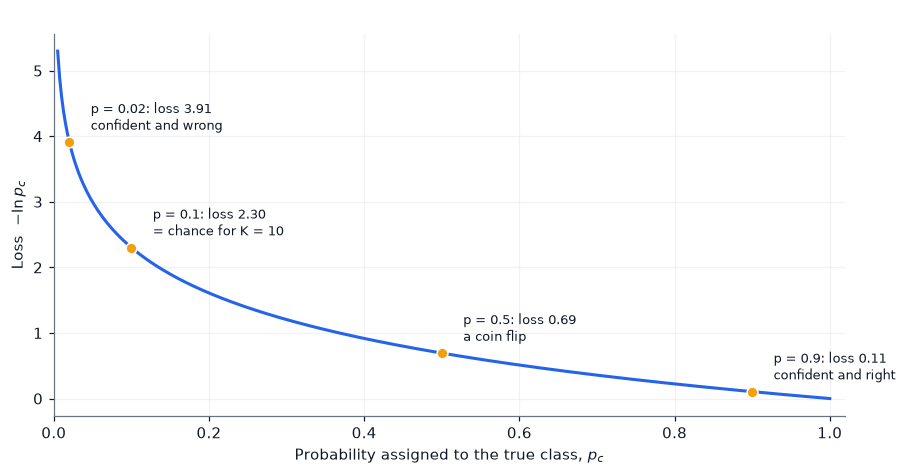

In [16]:
# Figure: the loss for one sample as a function of the probability assigned to the true class.
p_grid = np.linspace(0.005, 1.0, 400)
fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.plot(p_grid, -np.log(p_grid), color=COLORS["blue"])
marks = [(0.9, "confident and right"), (0.5, "a coin flip"), (0.1, "= chance for K = 10"), (0.02, "confident and wrong")]
for p_true, text in marks:
    loss_value = -np.log(p_true)
    ax.scatter([p_true], [loss_value], color=COLORS["orange"], zorder=5, s=50, edgecolor="white")
    ax.annotate(f"p = {p_true}: loss {loss_value:.2f}\n{text}", (p_true, loss_value), textcoords="offset points",
                xytext=(14, 8), fontsize=8.5, color=COLORS["dark"])
ax.set_xlabel(r"Probability assigned to the true class, $p_c$")
ax.set_ylabel(r"Loss  $-\ln p_c$")
ax.set_title("Cross-entropy punishes confident mistakes severely")
ax.set_xlim(0, 1.02)
finish(fig, "07_crossentropy_curve")

## 9. Mathematics III: the gradient of softmax + cross-entropy, and backpropagation

### 9.1 The gradient with respect to the logits

For one sample with one-hot target $y$ and $p = \operatorname{softmax}(z)$:

$$
\frac{\partial \ell}{\partial z_j}
= -\sum_{k} y_k \frac{\partial \ln p_k}{\partial z_j}
= -\sum_{k} y_k\,(\delta_{kj} - p_j)
= -y_j + p_j \sum_k y_k
= p_j - y_j .
$$

The gradient with respect to the logits is simply **prediction minus target**. It is small when the model is right and large when it is wrong. This simple form is the reason softmax and cross-entropy are almost always used together.

### 9.2 Backpropagation through our MLP

Consider the network we will train, with two hidden ReLU layers, for a batch of $N$ samples. Let $X \in \mathbb{R}^{N \times F}$ and let $Y \in \{0,1\}^{N \times K}$ be the one-hot targets.

**Forward pass**

$$
\begin{aligned}
Z_1 &= X W_1 + b_1, & A_1 &= \operatorname{ReLU}(Z_1),\\
Z_2 &= A_1 W_2 + b_2, & A_2 &= \operatorname{ReLU}(Z_2),\\
Z_3 &= A_2 W_3 + b_3, & P &= \operatorname{softmax}(Z_3),
\end{aligned}
\qquad
L = -\frac{1}{N} \sum_{i,k} Y_{ik} \ln P_{ik} .
$$

**Backward pass** (the chain rule applied layer by layer, from the output backwards):

$$
\begin{aligned}
dZ_3 &= \tfrac{1}{N}(P - Y), & dW_3 &= A_2^{\top} dZ_3, & db_3 &= \mathbf{1}^{\top} dZ_3,\\
dA_2 &= dZ_3 W_3^{\top}, & dZ_2 &= dA_2 \odot \mathbb{1}(Z_2 > 0), & dW_2 &= A_1^{\top} dZ_2,\\
db_2 &= \mathbf{1}^{\top} dZ_2, & dA_1 &= dZ_2 W_2^{\top}, & dZ_1 &= dA_1 \odot \mathbb{1}(Z_1 > 0),\\
dW_1 &= X^{\top} dZ_1, & db_1 &= \mathbf{1}^{\top} dZ_1 .
\end{aligned}
$$

### 9.3 A gradient check

How can we be sure that derivations like these are correct? By comparing them with the definition of the derivative. For each parameter $\theta$, the **numerical gradient** is

$$
\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon},
$$

and the agreement is measured with the **relative error**

$$
\frac{\lVert g_{\text{analytic}} - g_{\text{numeric}} \rVert}{\lVert g_{\text{analytic}} \rVert + \lVert g_{\text{numeric}} \rVert} .
$$

Values around $10^{-7}$ or smaller indicate a correct implementation. This technique — *gradient checking* — is a standard way to debug custom layers and losses.

In [17]:
def init_params(layer_sizes, seed=0):
    r = np.random.default_rng(seed)
    params = {}
    for i, (n_in, n_out) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:]), start=1):
        params[f"W{i}"] = r.normal(0, 0.5, size=(n_in, n_out))
        params[f"b{i}"] = r.normal(0, 0.1, size=(1, n_out))
    return params

def mlp_forward(X, params):
    Z1 = X @ params["W1"] + params["b1"];  A1 = np.maximum(0, Z1)
    Z2 = A1 @ params["W2"] + params["b2"]; A2 = np.maximum(0, Z2)
    Z3 = A2 @ params["W3"] + params["b3"]; P = softmax_np(Z3)
    return P, {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2, "P": P}

def mlp_loss(X, Y, params):
    P, _ = mlp_forward(X, params)
    return categorical_crossentropy_np(Y, P, eps=1e-12)

def mlp_backward(Y, params, cache):
    N = Y.shape[0]
    dZ3 = (cache["P"] - Y) / N
    grads = {"W3": cache["A2"].T @ dZ3, "b3": dZ3.sum(axis=0, keepdims=True)}
    dZ2 = (dZ3 @ params["W3"].T) * (cache["Z2"] > 0)
    grads.update({"W2": cache["A1"].T @ dZ2, "b2": dZ2.sum(axis=0, keepdims=True)})
    dZ1 = (dZ2 @ params["W2"].T) * (cache["Z1"] > 0)
    grads.update({"W1": cache["X"].T @ dZ1, "b1": dZ1.sum(axis=0, keepdims=True)})
    return grads

# A small random problem: 6 samples, 8 features, hidden sizes 5 and 4, 3 classes.
rg = np.random.default_rng(1)
X_chk = rg.normal(size=(6, 8))
Y_chk = np.eye(3)[rg.integers(0, 3, size=6)]
params = init_params([8, 5, 4, 3], seed=2)

P_chk, cache_chk = mlp_forward(X_chk, params)
analytic = mlp_backward(Y_chk, params, cache_chk)

def numerical_gradient(name, eps=1e-6):
    theta = params[name]
    grad = np.zeros_like(theta)
    for idx in np.ndindex(*theta.shape):
        original = theta[idx]
        theta[idx] = original + eps; loss_plus = mlp_loss(X_chk, Y_chk, params)
        theta[idx] = original - eps; loss_minus = mlp_loss(X_chk, Y_chk, params)
        theta[idx] = original
        grad[idx] = (loss_plus - loss_minus) / (2 * eps)
    return grad

print(f"{'parameter':>10} | {'shape':>10} | relative error")
for name in ["W1", "b1", "W2", "b2", "W3", "b3"]:
    g_num = numerical_gradient(name)
    g_ana = analytic[name]
    rel = np.linalg.norm(g_ana - g_num) / (np.linalg.norm(g_ana) + np.linalg.norm(g_num) + 1e-15)
    print(f"{name:>10} | {str(g_ana.shape):>10} | {rel:.2e}")
    assert rel < 1e-5, f"Gradient check failed for {name}"
print("\nAll analytic gradients match the numerical gradients.")

 parameter |      shape | relative error
        W1 |     (8, 5) | 3.13e-10
        b1 |     (1, 5) | 4.27e-10
        W2 |     (5, 4) | 1.88e-10
        b2 |     (1, 4) | 3.27e-10
        W3 |     (4, 3) | 1.07e-10
        b3 |     (1, 3) | 1.36e-10

All analytic gradients match the numerical gradients.


The backward pass derived above is exactly what a framework's **automatic differentiation** produces. When we call `model.fit()` in Keras, the backend computes these gradients for us; the optimizer then uses them for the parameter update $\theta \leftarrow \theta - \eta\, g$ (or a more refined variant such as Adam).

## 10. One-hot encoding of the labels

Neural networks work with numbers, and the class "index" $0, 1, \dots, 9$ has no numerical meaning: class 5 is not "between" classes 4 and 6. The **one-hot encoding** represents class $c$ as a vector of length $K$ with a 1 in position $c$:

$$
c = 2 \;\;\longrightarrow\;\; y = (0, 0, 1, 0, 0, 0, 0, 0, 0, 0) .
$$

For a whole dataset, labels become a matrix $Y \in \{0,1\}^{N \times K}$ with $\sum_k Y_{ik} = 1$. The encoding is reversible: $c = \arg\max_k Y_{ik}$.

Keras offers two equivalent ways to work with classification targets:

| Target storage | Loss | Shape of `y` |
|---|---|---|
| One-hot vectors | `categorical_crossentropy` | `(N, K)` |
| Integer labels | `sparse_categorical_crossentropy` | `(N,)` |

They compute the same number; the sparse version simply avoids storing a mostly-zero matrix. We use one-hot encoding in this notebook because it makes the mathematics of Section 8 explicit, and we verify the equivalence in Section 13.

In [18]:
Y_train = keras.utils.to_categorical(y_train, num_classes=N_CLASSES).astype("float32")
Y_val = keras.utils.to_categorical(y_val, num_classes=N_CLASSES).astype("float32")
Y_test = keras.utils.to_categorical(y_test, num_classes=N_CLASSES).astype("float32")

print("Integer labels:", y_train.shape, "-> one-hot:", Y_train.shape)
print("\nFirst three training proteins")
for i in range(3):
    print(f"  class index {y_train[i]} ({CLASS_ORDER[y_train[i]]}) -> {Y_train[i].astype(int)}")

# Checks: every row has exactly one 1, and the encoding is reversible.
assert np.all(Y_train.sum(axis=1) == 1)
assert np.array_equal(Y_train.argmax(axis=1), y_train)
print("\nRow sums are 1 and argmax recovers the integer labels.")

Integer labels: (1040,) -> one-hot: (1040, 10)

First three training proteins
  class index 1 (NUC) -> [0 1 0 0 0 0 0 0 0 0]
  class index 0 (CYT) -> [1 0 0 0 0 0 0 0 0 0]
  class index 2 (MIT) -> [0 0 1 0 0 0 0 0 0 0]

Row sums are 1 and argmax recovers the integer labels.


## 11. Designing the MLP

The input is a vector of 8 features; the output is a distribution over 10 classes. We use a small multilayer perceptron:

| Layer | Output shape | Parameters | Role |
|---|---|---|---|
| Input | `(None, 8)` | 0 | eight sequence-derived scores |
| Normalization | `(None, 8)` | 0 trainable | standardization using **training** statistics |
| Dense(32, ReLU) | `(None, 32)` | $8 \cdot 32 + 32 = 288$ | learn feature combinations |
| Dense(16, ReLU) | `(None, 16)` | $32 \cdot 16 + 16 = 528$ | learn higher-level combinations |
| Dense(10, softmax) | `(None, 10)` | $16 \cdot 10 + 10 = 170$ | class probabilities |

Total trainable parameters: $288 + 528 + 170 = 986$.

**Design reasoning.**

- *Why so small?* We have only about 1,000 training proteins. A model with many more parameters than samples is prone to overfitting (Notebook 06). Here the parameter count is of the same order as the sample size, which is already generous.
- *Why ReLU in hidden layers and softmax at the output?* ReLU is simple and works well in practice; softmax converts scores to the probability distribution required by the cross-entropy loss.
- *Why does the Normalization layer belong in the model?* The statistics are learned from training data only and travel with the model when it is saved.

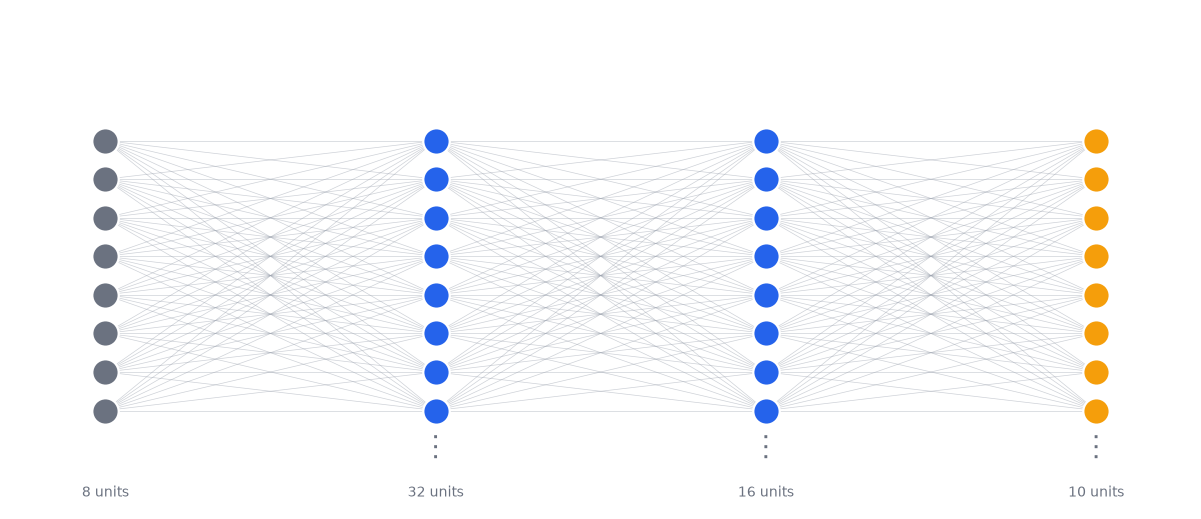

In [19]:
def draw_mlp(layer_sizes, layer_names, max_nodes=8):
    """Draw a schematic of a fully connected network (long layers are shown truncated)."""
    n_layers = len(layer_sizes)
    xs = np.linspace(0.08, 0.92, n_layers)
    layer_colors = [COLORS["gray"]] + [COLORS["blue"]] * (n_layers - 2) + [COLORS["orange"]]
    fig, ax = plt.subplots(figsize=(11, 4.8))
    positions = []
    for i, size in enumerate(layer_sizes):
        shown = min(size, max_nodes)
        ys = np.linspace(0.14, 0.86, shown) if shown > 1 else np.array([0.5])
        positions.append([(xs[i], y_) for y_ in ys])
    for i in range(n_layers - 1):
        for (x0, y0) in positions[i]:
            for (x1, y1) in positions[i + 1]:
                ax.plot([x0, x1], [y0, y1], color="#9CA3AF", linewidth=0.45, alpha=0.5, zorder=1)
    for i, pts in enumerate(positions):
        for (px, py) in pts:
            ax.scatter(px, py, s=300, color=layer_colors[i], edgecolor="white", linewidth=1.5, zorder=3)
        if layer_sizes[i] > max_nodes:
            ax.text(xs[i], 0.04, "\u22ee", ha="center", va="center", fontsize=18, color=COLORS["gray"])
        ax.text(xs[i], 1.0, layer_names[i], ha="center", va="bottom", fontsize=10, fontweight="bold")
        ax.text(xs[i], -0.06, f"{layer_sizes[i]} units", ha="center", va="top", fontsize=9, color=COLORS["gray"])
    ax.set_xlim(0, 1); ax.set_ylim(-0.12, 1.08); ax.set_axis_off()
    ax.set_title("MLP architecture used in this notebook (nodes truncated for display)", loc="left", pad=22)
    return fig

fig = draw_mlp([8, 32, 16, 10], ["Input\n(8 features)", "Dense + ReLU", "Dense + ReLU", "Dense + softmax\n(10 classes)"])
finish(fig, "08_mlp_architecture")

In [20]:
def build_classifier(name="yeast_mlp", hidden_units=(32, 16)):
    """Create a fresh, untrained classifier. Normalization statistics come from the TRAINING set only."""
    normalization = keras.layers.Normalization(axis=-1, name="normalize_features")
    normalization.adapt(X_train)
    layers = [keras.layers.Input(shape=(len(FEATURES),), name="features"), normalization]
    for i, units in enumerate(hidden_units, start=1):
        layers.append(keras.layers.Dense(units, activation="relu", name=f"hidden_{i}"))
    layers.append(keras.layers.Dense(N_CLASSES, activation="softmax", name="class_probabilities"))
    return keras.Sequential(layers, name=name)

model_preview = build_classifier()
model_preview.summary()

expected = (8 * 32 + 32) + (32 * 16 + 16) + (16 * 10 + 10)
trainable = sum(int(np.prod(w.shape)) for w in model_preview.trainable_weights)
print("Expected trainable parameters:", expected, "| counted:", trainable)
assert trainable == expected == 986

Model: "yeast_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize_features              │ (None, 8)              │            17 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,003 (3.92 KB)

 Trainable params: 986 (3.85 KB)

 Non-trainable params: 17 (72.00 B)

Expected trainable parameters: 986 | counted: 986


## 12. Evaluation mathematics and reference baselines

Before training, we need a language for *measuring* performance — especially for imbalanced data.

### 12.1 The confusion matrix

For $K$ classes, the confusion matrix $C \in \mathbb{N}^{K \times K}$ has entries

$$
C_{ij} = \#\{\text{samples with true class } i \text{ predicted as class } j\} .
$$

Rows are true classes, columns are predicted classes. The diagonal contains correct predictions.

### 12.2 Per-class metrics

For class $k$, treating it as "positive" and all others as "negative":

$$
\operatorname{Precision}_k = \frac{C_{kk}}{\sum_i C_{ik}}, \qquad
\operatorname{Recall}_k = \frac{C_{kk}}{\sum_j C_{kj}}, \qquad
F1_k = \frac{2\,\operatorname{Precision}_k \operatorname{Recall}_k}{\operatorname{Precision}_k + \operatorname{Recall}_k} .
$$

- **Precision**: of the proteins *predicted* as class $k$, which fraction truly belong to it?
- **Recall** (sensitivity): of the proteins that *truly* belong to class $k$, which fraction did we find?
- **F1** is the harmonic mean of the two; it is small if either is small.

### 12.3 Aggregating over classes

| Summary | Formula | Behaviour |
|---|---|---|
| Accuracy | $\sum_k C_{kk} \big/ \sum_{ij} C_{ij}$ | dominated by large classes |
| Macro-F1 | $\frac{1}{K}\sum_k F1_k$ | every class counts equally |
| Weighted-F1 | $\sum_k \frac{n_k}{N} F1_k$ | classes weighted by support $n_k$ |
| Micro-F1 | pooled over all decisions | equals accuracy in single-label multiclass problems |
| Balanced accuracy | $\frac{1}{K}\sum_k \operatorname{Recall}_k$ | mean per-class recall |

### 12.4 Matthews correlation coefficient (multiclass)

Let $t_k = \sum_j C_{kj}$ (true count), $p_k = \sum_i C_{ik}$ (predicted count), $c = \sum_k C_{kk}$, and $s = \sum_{ij} C_{ij}$. Then

$$
\operatorname{MCC} = \frac{c\,s - \sum_k p_k t_k}{\sqrt{\big(s^2 - \sum_k p_k^2\big)\big(s^2 - \sum_k t_k^2\big)}} \in [-1, 1] .
$$

It equals 1 for perfect prediction, about 0 for random prediction, and is usually more informative than accuracy under imbalance.

### 12.5 Baselines

Two trivial predictors give the reference point for "learned anything at all":

1. **Majority class:** always predict the most frequent class. Its accuracy equals the largest class's share.
2. **Prior sampling:** predict class $k$ with probability $\pi_k$ at random. Its expected accuracy is $\sum_k \pi_k^2$.

Any model must clearly beat both.

In [21]:
def confusion_matrix_np(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)            # rows = true class, columns = predicted class
    return cm

def classification_report_np(cm, labels):
    """Per-class precision, recall, F1, and support from a confusion matrix."""
    cm = np.asarray(cm)
    tp = np.diag(cm).astype(float)
    predicted = cm.sum(axis=0).astype(float)
    support = cm.sum(axis=1).astype(float)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    return pd.DataFrame({"precision": precision, "recall": recall, "f1": f1,
                         "support": support.astype(int)}, index=labels)

def summary_metrics(cm):
    """Accuracy, macro/weighted F1, balanced accuracy, and multiclass MCC from a confusion matrix."""
    cm = np.asarray(cm, dtype=float)
    rep = classification_report_np(cm, range(cm.shape[0]))
    present = rep["support"].values > 0           # classes that actually occur in the true labels
    total = cm.sum()
    t, p, c = cm.sum(axis=1), cm.sum(axis=0), np.trace(cm)
    denominator = np.sqrt((total**2 - np.sum(p**2)) * (total**2 - np.sum(t**2)))
    mcc = (c * total - np.sum(p * t)) / denominator if denominator > 0 else 0.0
    return {
        "accuracy": c / total,
        "macro_f1": rep.loc[present, "f1"].mean(),
        "weighted_f1": np.average(rep["f1"], weights=rep["support"]),
        "balanced_accuracy": rep.loc[present, "recall"].mean(),
        "mcc": mcc,
    }

# Verification on a tiny example where the answer can be checked by hand.
cm_toy = np.array([[8, 2, 0],
                   [1, 5, 0],
                   [0, 1, 3]])
rep_toy = classification_report_np(cm_toy, ["a", "b", "c"])
display(rep_toy.round(3))
print("Precision of class a = 8/(8+1+0) =", round(8 / 9, 3), "| recall of class a = 8/(8+2+0) =", 8 / 10)
print({k: round(float(v), 4) for k, v in summary_metrics(cm_toy).items()})

# Micro-F1 equals accuracy for single-label multiclass classification:
micro_precision = np.trace(cm_toy) / cm_toy.sum()
print("Micro precision = micro recall = accuracy =", round(micro_precision, 4))

,precision,recall,f1,support
a,0.889,0.800,0.842,10
b,0.625,0.833,0.714,6
c,1.000,0.750,0.857,4


Precision of class a = 8/(8+1+0) = 0.889 | recall of class a = 8/(8+2+0) = 0.8
{'accuracy': 0.8, 'macro_f1': 0.8045, 'weighted_f1': 0.8068, 'balanced_accuracy': 0.7944, 'mcc': 0.6883}
Micro precision = micro recall = accuracy = 0.8


In [22]:
# Baselines evaluated on the VALIDATION set.
majority_class = int(np.argmax(np.bincount(y_train)))
majority_pred = np.full_like(y_val, majority_class)
cm_majority = confusion_matrix_np(y_val, majority_pred, N_CLASSES)
metrics_majority = summary_metrics(cm_majority)

expected_prior_accuracy = float(np.sum(train_freq**2))

print(f"Majority-class baseline predicts always '{CLASS_ORDER[majority_class]}'")
print(f"  accuracy    : {metrics_majority['accuracy']:.3f}")
print(f"  macro-F1    : {metrics_majority['macro_f1']:.3f}")
print(f"  MCC         : {metrics_majority['mcc']:.3f}")
print(f"Prior-sampling baseline, expected accuracy: {expected_prior_accuracy:.3f}")

Majority-class baseline predicts always 'CYT'
  accuracy    : 0.311
  macro-F1    : 0.047
  MCC         : 0.000
Prior-sampling baseline, expected accuracy: 0.224


The majority-class baseline (always `CYT`) already reaches about 30% accuracy — **without using any feature** — but its macro-F1 is very low because it never finds nine of the ten classes. This is the key lesson of imbalanced classification: *the choice of metric decides what "good" means*.

## 13. Training the baseline MLP

We compile the model with the Adam optimizer, `categorical_crossentropy`, and accuracy as a metric, then train with early stopping on the validation loss.

We also write a small **custom callback** that computes the **macro-F1** on the validation set after every epoch (using the function from Section 12). Keras reports accuracy by default, but we have just seen that accuracy is not enough for this dataset.

In [23]:
class MacroF1Callback(keras.callbacks.Callback):
    """Record the validation macro-F1 after every epoch (for monitoring and plotting)."""
    def __init__(self, X_eval, y_eval_int, n_classes):
        super().__init__()
        self.X_eval, self.y_eval, self.n_classes = X_eval, y_eval_int, n_classes
        self.macro_f1 = []
    def on_train_begin(self, logs=None):
        self.macro_f1 = []
    def on_epoch_end(self, epoch, logs=None):
        predicted = np.argmax(self.model.predict(self.X_eval, verbose=0), axis=1)
        cm = confusion_matrix_np(self.y_eval, predicted, self.n_classes)
        self.macro_f1.append(summary_metrics(cm)["macro_f1"])

def train_classifier(name, class_weight=None, seed=SEED, max_epochs=300):
    """Train a fresh classifier and return the model, its history, and the macro-F1 callback."""
    keras.utils.set_random_seed(seed)
    model = build_classifier(name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=[keras.metrics.CategoricalAccuracy(name="accuracy")],
    )
    f1_callback = MacroF1Callback(X_val, y_val, N_CLASSES)
    callbacks = [
        f1_callback,
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5),
    ]
    history = model.fit(
        X_train, Y_train, validation_data=(X_val, Y_val),
        epochs=max_epochs, batch_size=32, class_weight=class_weight,
        callbacks=callbacks, verbose=0,
    )
    return model, history, f1_callback

baseline_model, baseline_history, baseline_f1 = train_classifier("baseline_mlp")

baseline_best_epoch = int(np.argmin(baseline_history.history["val_loss"])) + 1
print("Epochs run          :", len(baseline_history.history["loss"]))
print("Best epoch (val_loss):", baseline_best_epoch)
print("Best validation loss :", round(min(baseline_history.history["val_loss"]), 4),
      f"(prior-only reference: {prior_val_loss:.4f})")

Epochs run          : 59
Best epoch (val_loss): 34
Best validation loss : 1.102 (prior-only reference: 1.7309)


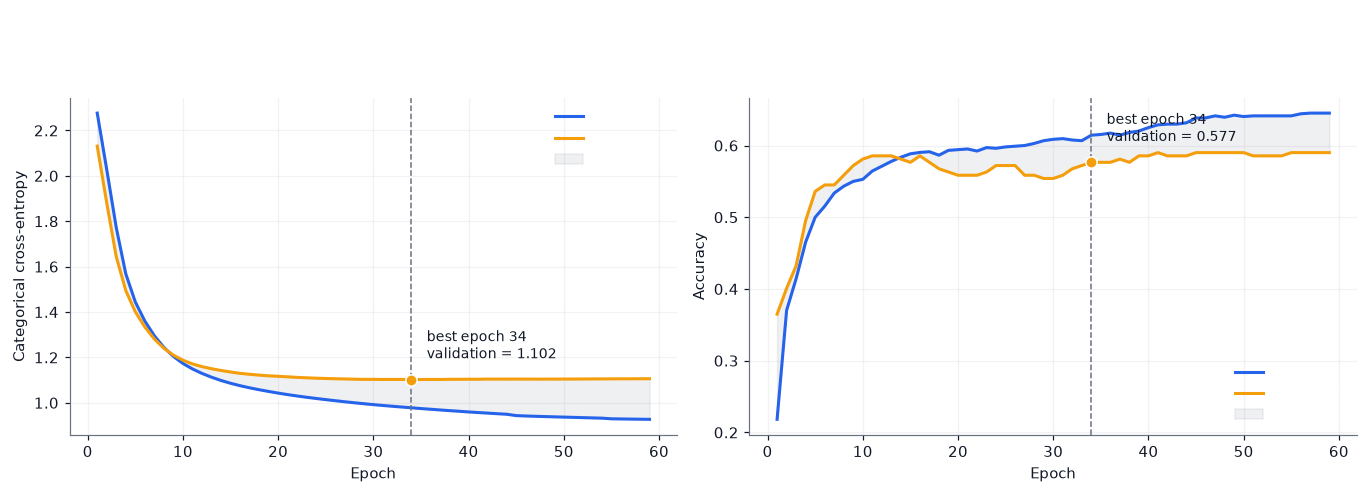

In [24]:
def plot_learning_curves(history, title, name, best_epoch=None, loss_label="Categorical cross-entropy"):
    """Learning curves with the generalization gap shaded and the best epoch marked."""
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    if best_epoch is None:
        best_epoch = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
    for ax, key, ylabel in zip(axes, ["loss", "accuracy"], [loss_label, "Accuracy"]):
        train_curve, val_curve = np.array(h[key]), np.array(h["val_" + key])
        ax.plot(epochs, train_curve, color=COLORS["blue"], label="Training")
        ax.plot(epochs, val_curve, color=COLORS["orange"], label="Validation")
        ax.fill_between(epochs, train_curve, val_curve, color=COLORS["gray"], alpha=0.10, label="Gap")
        ax.axvline(best_epoch, color=COLORS["gray"], linestyle="--", linewidth=1)
        ax.scatter([best_epoch], [val_curve[best_epoch - 1]], color=COLORS["orange"], s=55, zorder=5, edgecolor="white")
        ax.annotate(f"best epoch {best_epoch}\nvalidation = {val_curve[best_epoch - 1]:.3f}",
                    (best_epoch, val_curve[best_epoch - 1]), textcoords="offset points", xytext=(10, 14),
                    fontsize=9, color=COLORS["dark"])
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
        ax.set_title("Loss" if key == "loss" else "Accuracy")
        ax.legend(loc="best")
    fig.suptitle(title, fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.03)
    finish(fig, name)

plot_learning_curves(baseline_history, "Baseline MLP: learning curves", "09_baseline_learning_curves", baseline_best_epoch)

Compare your own curves with this pattern, which is typical for small datasets: the training loss keeps decreasing while the validation loss flattens and then starts to rise, because the model begins to memorize training proteins. The dashed line marks the epoch with the best validation loss, and early stopping restored the weights from that epoch. Regularization techniques that push this point further are the topic of Notebook 06.

## 14. Evaluating on the validation set

We use `predict()` to obtain the probability matrix $P \in \mathbb{R}^{N \times K}$, then take the arg max. All numbers in this section are computed on the **validation** set; the test set remains untouched.

### 14.1 Does Keras compute the same loss as our formulas?

A good habit is to check that the framework's numbers agree with the mathematics we derived. Keras provides the loss both for one-hot and for integer targets; the manual formula uses the probability of the true class only.

In [25]:
val_probs = baseline_model.predict(X_val, verbose=0)
val_pred = np.argmax(val_probs, axis=1)

# Three ways to compute the same loss.
cce = keras.losses.CategoricalCrossentropy()
scce = keras.losses.SparseCategoricalCrossentropy()
loss_onehot = float(keras.ops.convert_to_numpy(cce(Y_val, val_probs)))
loss_sparse = float(keras.ops.convert_to_numpy(scce(y_val, val_probs)))
loss_manual = float(-np.mean(np.log(np.clip(val_probs[np.arange(len(y_val)), y_val], 1e-7, 1.0))))

print(f"Keras, one-hot targets   : {loss_onehot:.5f}")
print(f"Keras, integer targets   : {loss_sparse:.5f}")
print(f"Manual  -mean(ln p_true) : {loss_manual:.5f}")
assert np.allclose([loss_onehot, loss_sparse], loss_manual, rtol=1e-4)

# Keras's evaluate() should also agree with our accuracy computation.
keras_results = baseline_model.evaluate(X_val, Y_val, verbose=0, return_dict=True)
print(f"\nKeras evaluate(): loss={keras_results['loss']:.5f}, accuracy={keras_results['accuracy']:.4f}")
print(f"NumPy accuracy  : {np.mean(val_pred == y_val):.4f}")

Keras, one-hot targets   : 1.10203
Keras, integer targets   : 1.10203
Manual  -mean(ln p_true) : 1.10203

Keras evaluate(): loss=1.10203, accuracy=0.5766
NumPy accuracy  : 0.5766


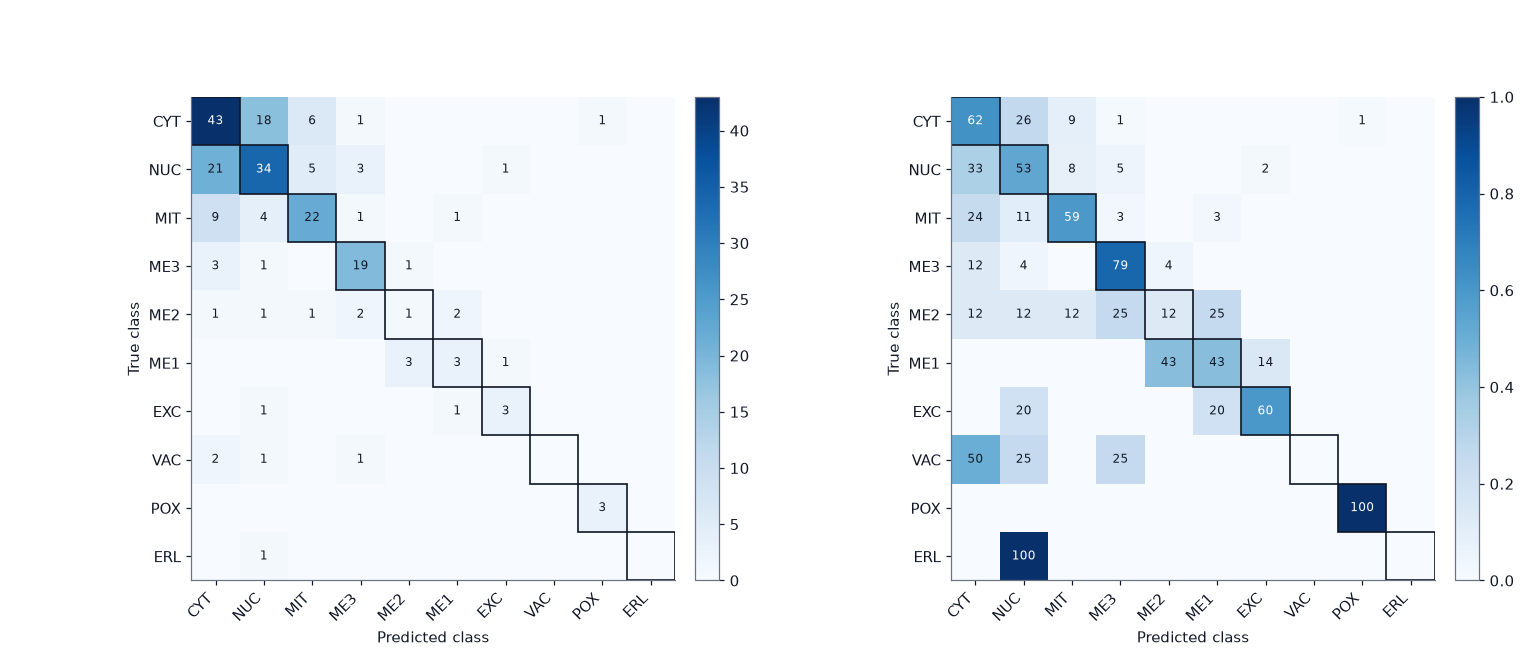

In [26]:
def plot_confusion_pair(cm, labels, title, name):
    """Confusion matrix as counts (left) and as row percentages = per-class recall (right)."""
    cm = np.asarray(cm)
    K = len(labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    normalized = np.divide(cm, row_sums, out=np.zeros(cm.shape, dtype=float), where=row_sums > 0)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
    panels = [(axes[0], cm, "Counts", cm.max()), (axes[1], normalized, "Row-normalized: % of each true class", 1.0)]
    for ax, data, ptitle, vmax in panels:
        image = ax.imshow(data, cmap="Blues", vmin=0, vmax=vmax)
        ax.set_xticks(range(K)); ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.set_yticks(range(K)); ax.set_yticklabels(labels)
        ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
        ax.set_title(ptitle); ax.grid(False)
        for i in range(K):
            for j in range(K):
                value = data[i, j]
                if value > 0:
                    text = f"{int(value)}" if vmax == cm.max() and data is cm else f"{100 * value:.0f}"
                    ax.text(j, i, text, ha="center", va="center", fontsize=8,
                            color="white" if value > 0.55 * vmax else COLORS["dark"])
        for k in range(K):
            ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1, fill=False, edgecolor=COLORS["dark"], linewidth=1.1))
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
    fig.suptitle(title, fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.02)
    finish(fig, name)

def plot_per_class_metrics(report, title, name):
    """Grouped bars of precision, recall, and F1 for every class, with the macro-F1 as a reference line."""
    x = np.arange(len(report)); width = 0.26
    fig, ax = plt.subplots(figsize=(11.5, 4.5))
    for offset, column, color, label in [(-width, "precision", COLORS["blue"], "Precision"),
                                         (0, "recall", COLORS["orange"], "Recall"),
                                         (width, "f1", COLORS["green"], "F1")]:
        ax.bar(x + offset, report[column], width, color=color, label=label, edgecolor="white")
    present = report["support"] > 0
    macro = report.loc[present, "f1"].mean()
    ax.axhline(macro, color=COLORS["dark"], linestyle="--", linewidth=1)
    ax.text(len(report) - 0.5, macro + 0.02, f"macro-F1 = {macro:.2f}", ha="right", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{code_name}\n(n={int(n)})" for code_name, n in zip(report.index, report["support"])])
    ax.set_ylim(0, 1.1); ax.set_ylabel("Score"); ax.set_title(title)
    ax.grid(axis="x", visible=False); ax.legend(ncol=3, loc="upper right", bbox_to_anchor=(1.0, 1.12))
    finish(fig, name)

cm_val = confusion_matrix_np(y_val, val_pred, N_CLASSES)
plot_confusion_pair(cm_val, CLASS_ORDER, "Baseline MLP — validation confusion matrix", "10_baseline_confusion_validation")

,precision,recall,f1,support
CYT,0.544,0.623,0.581,69
NUC,0.557,0.531,0.544,64
MIT,0.647,0.595,0.620,37
ME3,0.704,0.792,0.745,24
ME2,0.200,0.125,0.154,8
ME1,0.429,0.429,0.429,7
EXC,0.600,0.600,0.600,5
VAC,0.000,0.000,0.000,4
POX,0.750,1.000,0.857,3
ERL,0.000,0.000,0.000,1


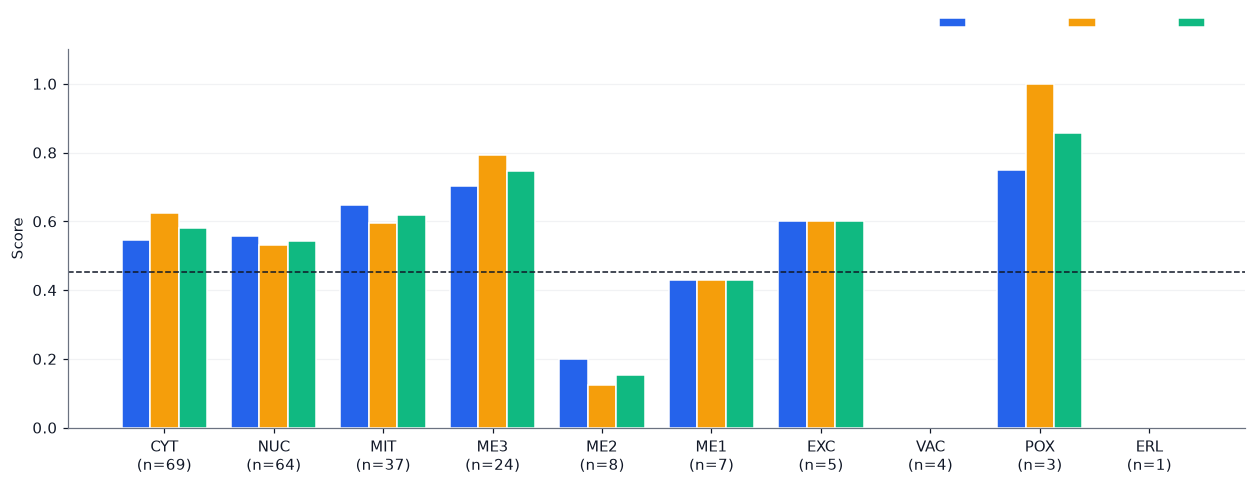

,Majority baseline,Baseline MLP
accuracy,0.311,0.577
macro_f1,0.047,0.453
weighted_f1,0.147,0.565
balanced_accuracy,0.100,0.469
mcc,0.000,0.450


In [27]:
report_val = classification_report_np(cm_val, CLASS_ORDER)
display(report_val.round(3))
plot_per_class_metrics(report_val, "Baseline MLP — per-class metrics on the validation set", "11_baseline_per_class_validation")

baseline_metrics = summary_metrics(cm_val)
comparison = pd.DataFrame({"Majority baseline": summary_metrics(cm_majority),
                           "Baseline MLP": baseline_metrics}).round(3)
display(comparison)

**How to read these results** (compare with your own numbers):

- Compare accuracy with the majority baseline: if it is clearly higher, the model has learned structure from the features.
- Compare macro-F1 with accuracy. On this dataset, macro-F1 is normally **lower than accuracy**: the large classes (`CYT`, `NUC`, `MIT`, `ME3`) are usually handled reasonably, while rare classes are found less reliably. Their recall is based on very few validation samples, so these numbers are noisy.
- Look for confusion between `CYT` and `NUC`. Both are soluble proteins without organelle-targeting signals, so overlapping features and some confusion are expected.
- Look at the three membrane classes (`ME1`, `ME2`, `ME3`). They differ only in signal-sequence details, so confusion among them is biologically understandable.

Next we look at the **training dynamics of the metric we care about**, macro-F1, which the custom callback recorded.

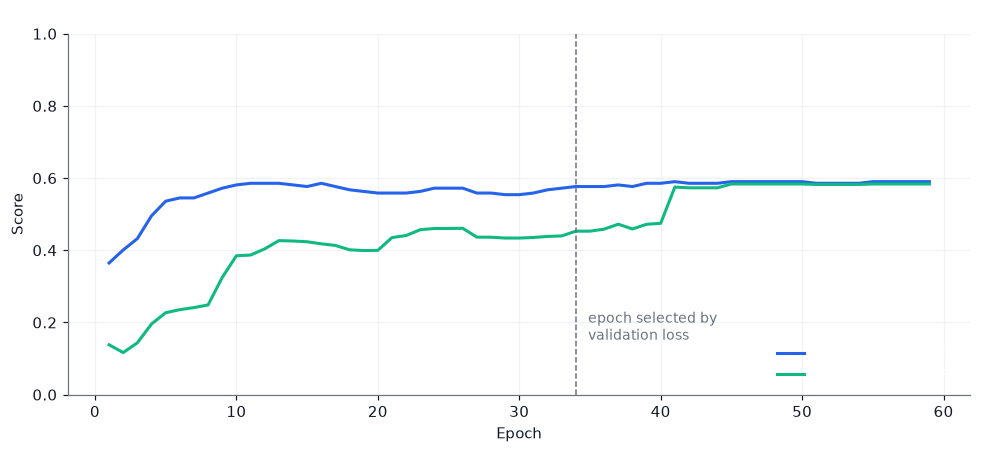

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.2))
epochs = np.arange(1, len(baseline_f1.macro_f1) + 1)
ax.plot(epochs, baseline_history.history["val_accuracy"], color=COLORS["blue"], label="Validation accuracy")
ax.plot(epochs, baseline_f1.macro_f1, color=COLORS["green"], label="Validation macro-F1")
ax.axvline(baseline_best_epoch, color=COLORS["gray"], linestyle="--", linewidth=1)
ax.annotate("epoch selected by\nvalidation loss", (baseline_best_epoch, ax.get_ylim()[0]), textcoords="offset points",
            xytext=(8, 14), fontsize=9, color=COLORS["gray"])
ax.set_xlabel("Epoch"); ax.set_ylabel("Score"); ax.set_ylim(0, 1)
ax.set_title("Accuracy rises quickly; macro-F1 is lower and noisier")
ax.legend(loc="lower right")
finish(fig, "12_accuracy_vs_macro_f1")

## 15. Handling class imbalance with class weights

With the standard loss every **sample** has the same influence, so large classes dominate the gradient. A common remedy is to give the samples of class $k$ a weight $w_k$:

$$
L_w = \frac{1}{N} \sum_{i=1}^{N} w_{c_i}\, \ell\big(y^{(i)}, p^{(i)}\big),
\qquad
\frac{\partial L_w}{\partial z^{(i)}} = \frac{w_{c_i}}{N}\,\big(p^{(i)} - y^{(i)}\big) .
$$

Rare-class mistakes now produce larger gradients. The classic "balanced" choice is

$$
w_k = \frac{N}{K\, n_k},
$$

which makes every class contribute the same *total* weight $w_k n_k = N/K$.

### 15.1 Why we soften the weights

For `ERL` we have about 3 training proteins. Fully balanced weights would give each of them a weight above 30, so the model could simply memorize those 3 points. We therefore use a **softened** version,

$$
w_k \propto \left(\frac{N}{K\, n_k}\right)^{\alpha}, \qquad 0 \le \alpha \le 1,
$$

and rescale so that the average weight over the training samples is 1:

$$
\sum_k n_k\, w_k = N .
$$

(The rescaling keeps the effective learning rate comparable to the unweighted run.) Here $\alpha = 0$ means no weighting and $\alpha = 1$ means fully balanced. We use $\alpha = 0.5$.

### 15.2 The trade-off

Class weights typically **increase recall** of rare classes and **decrease their precision** (more false alarms), and can slightly reduce overall accuracy. Which trade-off is right depends on the application, for example whether missing a rare localization is more costly than a false alarm.

In [29]:
def make_class_weights(labels, n_classes, alpha=0.5):
    """Softened inverse-frequency class weights, rescaled so that the mean sample weight is 1."""
    n_k = np.bincount(labels, minlength=n_classes).astype(float)
    raw = (len(labels) / (n_classes * n_k)) ** alpha
    scale = np.sum(n_k * raw) / len(labels)
    return raw / scale

weights_balanced = make_class_weights(y_train, N_CLASSES, alpha=1.0)
weights_soft = make_class_weights(y_train, N_CLASSES, alpha=0.5)

weight_table = pd.DataFrame({
    "n_train": np.bincount(y_train, minlength=N_CLASSES),
    "w (alpha=1.0, balanced)": weights_balanced,
    "w (alpha=0.5, used)": weights_soft,
}, index=CLASS_ORDER).round(2)
display(weight_table)

# Both versions satisfy the normalization sum_k n_k w_k = N.
for w in (weights_balanced, weights_soft):
    assert np.isclose(np.sum(np.bincount(y_train, minlength=N_CLASSES) * w), len(y_train))

class_weight_dict = {k: float(w) for k, w in enumerate(weights_soft)}

,n_train,"w (alpha=1.0, balanced)","w (alpha=0.5, used)"
CYT,325,0.32,0.67
NUC,301,0.35,0.70
MIT,170,0.61,0.93
ME3,115,0.90,1.13
ME2,35,2.97,2.05
ME1,30,3.47,2.22
EXC,25,4.16,2.43
VAC,22,4.73,2.59
POX,14,7.43,3.24
ERL,3,34.67,7.01


Epochs run           : 46
Best epoch (val_loss): 21
Note: the TRAINING loss of this model is weighted, so it is not directly comparable to the baseline's.


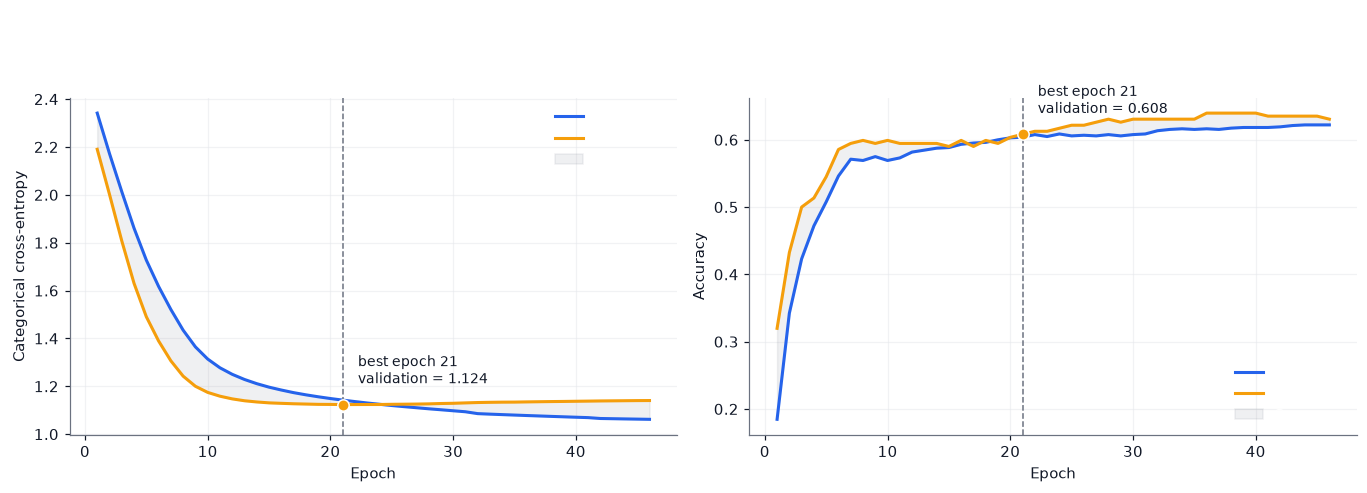

In [30]:
weighted_model, weighted_history, weighted_f1 = train_classifier("weighted_mlp", class_weight=class_weight_dict)
weighted_best_epoch = int(np.argmin(weighted_history.history["val_loss"])) + 1

print("Epochs run           :", len(weighted_history.history["loss"]))
print("Best epoch (val_loss):", weighted_best_epoch)
print("Note: the TRAINING loss of this model is weighted, so it is not directly comparable to the baseline's.")
plot_learning_curves(weighted_history, "Class-weighted MLP: learning curves", "13_weighted_learning_curves", weighted_best_epoch)

In [31]:
weighted_probs = weighted_model.predict(X_val, verbose=0)
weighted_pred = np.argmax(weighted_probs, axis=1)
cm_val_weighted = confusion_matrix_np(y_val, weighted_pred, N_CLASSES)
report_val_weighted = classification_report_np(cm_val_weighted, CLASS_ORDER)
weighted_metrics = summary_metrics(cm_val_weighted)

comparison = pd.DataFrame({"Majority baseline": summary_metrics(cm_majority),
                           "Baseline MLP": baseline_metrics,
                           "Class-weighted MLP": weighted_metrics}).round(3)
display(comparison)

,Majority baseline,Baseline MLP,Class-weighted MLP
accuracy,0.311,0.577,0.608
macro_f1,0.047,0.453,0.557
weighted_f1,0.147,0.565,0.602
balanced_accuracy,0.100,0.469,0.618
mcc,0.000,0.450,0.500


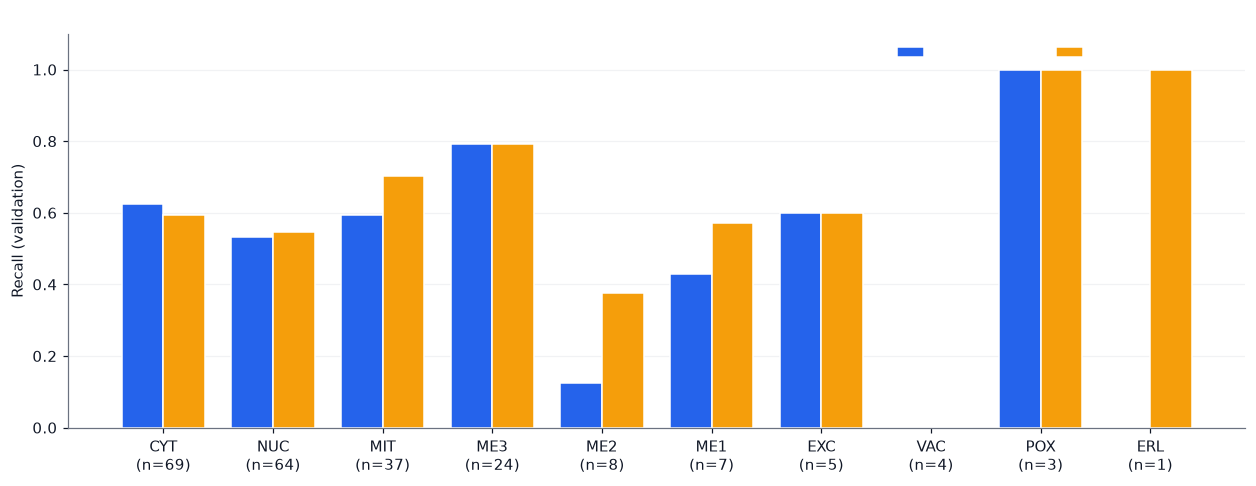

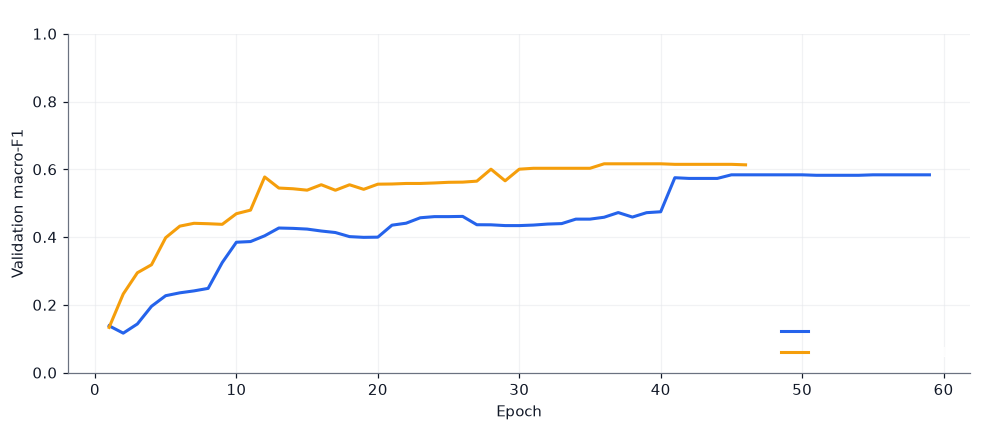

In [32]:
# Figure: per-class recall of the two models side by side.
x = np.arange(N_CLASSES); width = 0.38
fig, ax = plt.subplots(figsize=(11.5, 4.5))
ax.bar(x - width / 2, report_val["recall"], width, color=COLORS["blue"], label="Baseline MLP", edgecolor="white")
ax.bar(x + width / 2, report_val_weighted["recall"], width, color=COLORS["orange"], label="Class-weighted MLP", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels([f"{c}\n(n={int(n)})" for c, n in zip(CLASS_ORDER, report_val["support"])])
ax.set_ylim(0, 1.1); ax.set_ylabel("Recall (validation)")
ax.set_title("Class weights change which classes the model finds")
ax.grid(axis="x", visible=False); ax.legend(ncol=2, loc="upper right")
finish(fig, "14_recall_comparison")

fig, ax = plt.subplots(figsize=(9, 4.0))
ax.plot(np.arange(1, len(baseline_f1.macro_f1) + 1), baseline_f1.macro_f1, color=COLORS["blue"], label="Baseline MLP")
ax.plot(np.arange(1, len(weighted_f1.macro_f1) + 1), weighted_f1.macro_f1, color=COLORS["orange"], label="Class-weighted MLP")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation macro-F1"); ax.set_ylim(0, 1)
ax.set_title("Validation macro-F1 during training")
ax.legend(loc="lower right")
finish(fig, "15_macro_f1_comparison")

Remember the limits of this comparison: one training run per model, one validation split, and rare classes with a handful of validation samples. Differences of a few hundredths in macro-F1 can be noise. A rigorous comparison uses repeated runs or cross-validation (Notebook 07). Here we only need a **pre-declared rule** for choosing between the two: *we select the model with the higher validation macro-F1; in case of a tie we prefer the simpler (unweighted) model.* We decide this before touching the test set.

## 16. Final evaluation on the test set

The selection rule is applied using **validation** results only. Then the chosen model is evaluated on the test set **exactly once**.

In [33]:
candidates = {"Baseline MLP": (baseline_model, baseline_metrics["macro_f1"]),
              "Class-weighted MLP": (weighted_model, weighted_metrics["macro_f1"])}

# Pre-declared rule: higher validation macro-F1; ties go to the simpler (unweighted) model.
if weighted_metrics["macro_f1"] > baseline_metrics["macro_f1"]:
    selected_name = "Class-weighted MLP"
else:
    selected_name = "Baseline MLP"
selected_model = candidates[selected_name][0]
print("Validation macro-F1:", {k: round(float(v[1]), 3) for k, v in candidates.items()})
print("Selected model     :", selected_name)

Validation macro-F1: {'Baseline MLP': 0.453, 'Class-weighted MLP': 0.557}
Selected model     : Class-weighted MLP


Selected model: Class-weighted MLP
{'accuracy': 0.613, 'macro_f1': 0.583, 'weighted_f1': 0.606, 'balanced_accuracy': 0.626, 'mcc': 0.506}
Keras test loss: 1.1604  (prior-only reference on validation: 1.7309)


,precision,recall,f1,support
CYT,0.565,0.696,0.623,69
NUC,0.708,0.531,0.607,64
MIT,0.500,0.432,0.464,37
ME3,0.815,0.917,0.863,24
ME2,0.364,0.500,0.421,8
ME1,0.833,0.714,0.769,7
EXC,0.500,0.800,0.615,5
VAC,0.000,0.000,0.000,4
POX,1.000,0.667,0.800,3
ERL,0.500,1.000,0.667,1


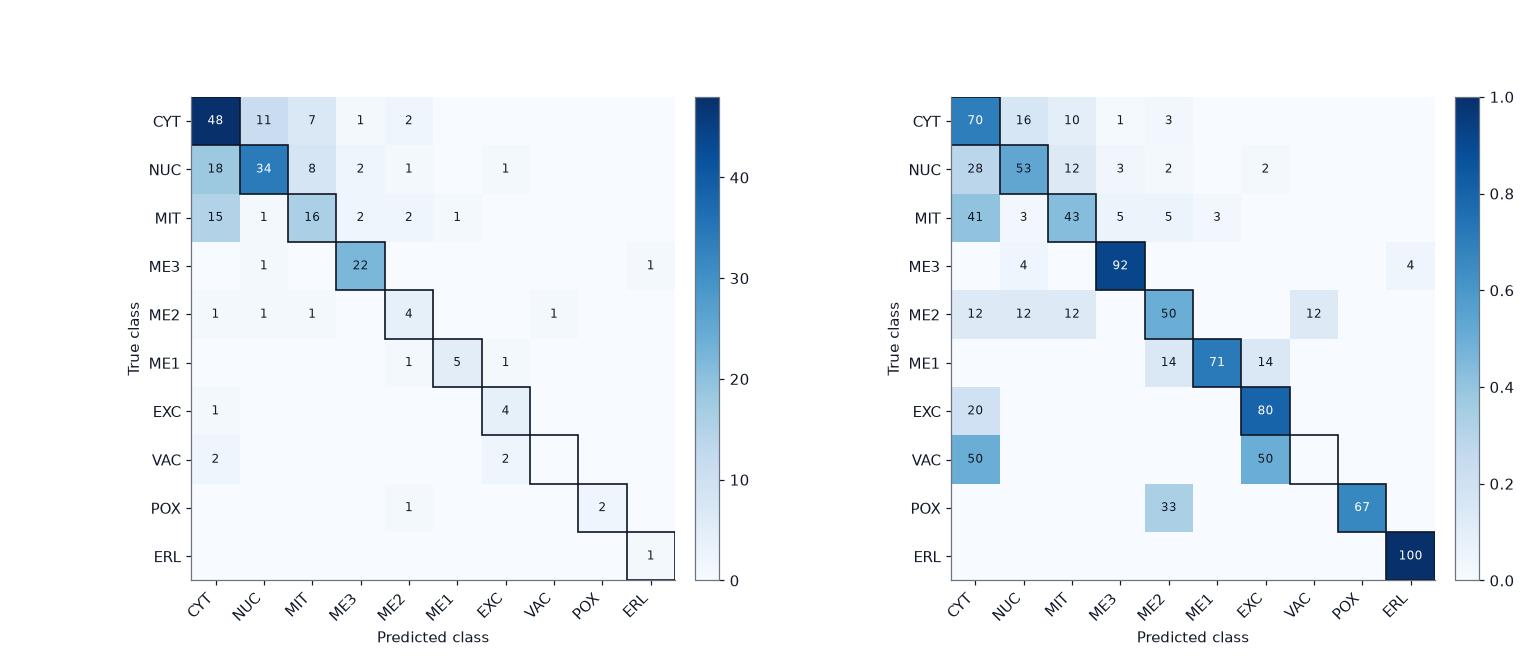

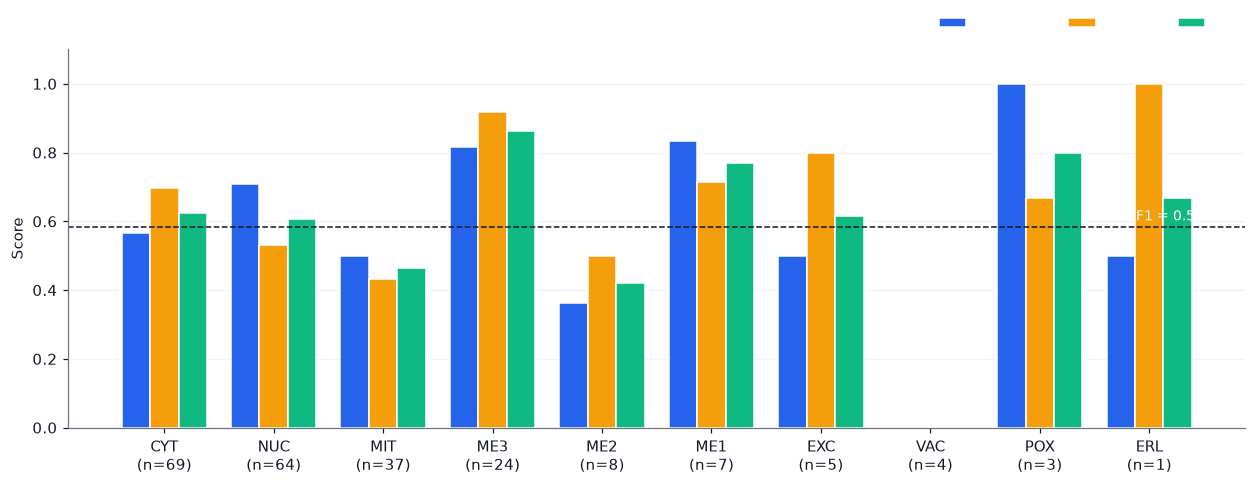

In [34]:
test_probs = selected_model.predict(X_test, verbose=0)
test_pred = np.argmax(test_probs, axis=1)

cm_test = confusion_matrix_np(y_test, test_pred, N_CLASSES)
report_test = classification_report_np(cm_test, CLASS_ORDER)
test_metrics = summary_metrics(cm_test)

# Consistency check with Keras.
keras_test = selected_model.evaluate(X_test, Y_test, verbose=0, return_dict=True)
assert np.isclose(keras_test["accuracy"], test_metrics["accuracy"], atol=1e-6)

print(f"Selected model: {selected_name}")
print({k: round(float(v), 3) for k, v in test_metrics.items()})
print(f"Keras test loss: {keras_test['loss']:.4f}  (prior-only reference on validation: {prior_val_loss:.4f})")
display(report_test.round(3))

plot_confusion_pair(cm_test, CLASS_ORDER, f"{selected_name} — test confusion matrix", "16_test_confusion")
plot_per_class_metrics(report_test, f"{selected_name} — per-class metrics on the test set", "17_test_per_class")

### 16.1 How uncertain is the test result? A bootstrap confidence interval

A test metric is computed on a finite sample, so it has sampling uncertainty. The **bootstrap** estimates it by resampling the test set with replacement:

1. Draw $N_{\text{test}}$ samples **with replacement** from the test set.
2. Recompute the metric on this resample.
3. Repeat $B$ times (here $B = 2000$).
4. The **95% percentile interval** is the range between the 2.5th and the 97.5th percentiles of the $B$ metric values.

This only captures uncertainty due to *which test proteins we happen to have*. It does not capture uncertainty from model initialization, from the choice of split, or from a shift to different data.

Test accuracy: 0.613  (95% bootstrap interval: 0.550 to 0.676)
Test macro-F1: 0.583  (95% bootstrap interval: 0.467 to 0.665)


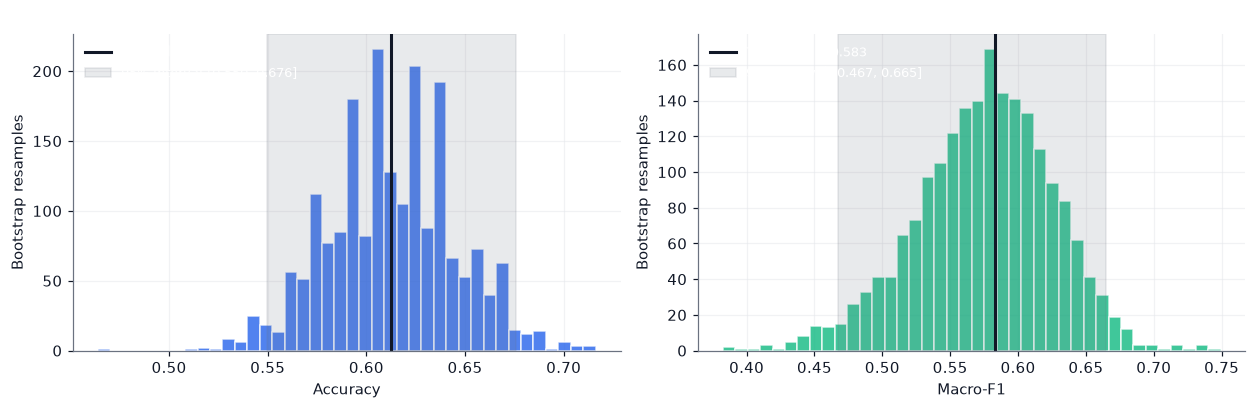

In [35]:
def bootstrap_metrics(y_true, y_pred, n_classes, n_boot=2000, seed=0):
    resampler = np.random.default_rng(seed)
    n = len(y_true)
    accuracies, macro_f1s = [], []
    for _ in range(n_boot):
        idx = resampler.integers(0, n, size=n)
        m = summary_metrics(confusion_matrix_np(y_true[idx], y_pred[idx], n_classes))
        accuracies.append(m["accuracy"]); macro_f1s.append(m["macro_f1"])
    return np.array(accuracies), np.array(macro_f1s)

boot_acc, boot_f1 = bootstrap_metrics(y_test, test_pred, N_CLASSES)
acc_low, acc_high = np.percentile(boot_acc, [2.5, 97.5])
f1_low, f1_high = np.percentile(boot_f1, [2.5, 97.5])
print(f"Test accuracy: {test_metrics['accuracy']:.3f}  (95% bootstrap interval: {acc_low:.3f} to {acc_high:.3f})")
print(f"Test macro-F1: {test_metrics['macro_f1']:.3f}  (95% bootstrap interval: {f1_low:.3f} to {f1_high:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, values, point, low, high, label, color in [
        (axes[0], boot_acc, test_metrics["accuracy"], acc_low, acc_high, "Accuracy", COLORS["blue"]),
        (axes[1], boot_f1, test_metrics["macro_f1"], f1_low, f1_high, "Macro-F1", COLORS["green"])]:
    ax.hist(values, bins=40, color=color, alpha=0.8, edgecolor="white")
    ax.axvline(point, color=COLORS["dark"], linewidth=2, label=f"Test value = {point:.3f}")
    ax.axvspan(low, high, color=COLORS["gray"], alpha=0.15, label=f"95% interval [{low:.3f}, {high:.3f}]")
    ax.set_xlabel(label); ax.set_ylabel("Bootstrap resamples"); ax.set_title(f"Bootstrap distribution: {label}")
    ax.legend(loc="upper left", fontsize=8.5)
finish(fig, "18_bootstrap_intervals")

Expect the macro-F1 interval to be much **wider** than the accuracy interval. Rare classes contribute with equal weight to macro-F1 but have almost no test samples, so a single protein can change their F1 from 0 to 1. This is a quantitative demonstration of the warning in Section 5.

## 17. Error analysis

A confusion matrix tells us *which* classes are mixed up; looking at individual errors tells us *how* the model is wrong. We list the most frequent confusion pairs and the proteins the model misclassifies with the highest confidence.

In [36]:
# Most frequent confusions on the test set (off-diagonal cells).
off_diagonal = [(cm_test[i, j], CLASS_ORDER[i], CLASS_ORDER[j]) for i in range(N_CLASSES) for j in range(N_CLASSES)
                if i != j and cm_test[i, j] > 0]
off_diagonal.sort(reverse=True)
print("Most frequent confusions (true -> predicted):")
for count, true_code, pred_code in off_diagonal[:6]:
    print(f"  {true_code} -> {pred_code}: {count}")

# Most confident mistakes.
wrong = np.flatnonzero(test_pred != y_test)
confidence = test_probs[wrong, test_pred[wrong]]
order = wrong[np.argsort(-confidence)]
error_table = pd.DataFrame({
    "protein": names_test[order[:8]],
    "true": [CLASS_ORDER[k] for k in y_test[order[:8]]],
    "predicted": [CLASS_ORDER[k] for k in test_pred[order[:8]]],
    "confidence in prediction": test_probs[order[:8], test_pred[order[:8]]].round(3),
    "probability of true class": test_probs[order[:8], y_test[order[:8]]].round(3),
})
print(f"\nMisclassified test proteins: {len(wrong)} of {len(y_test)}")
display(error_table)

Most frequent confusions (true -> predicted):
  NUC -> CYT: 18
  MIT -> CYT: 15
  CYT -> NUC: 11
  NUC -> MIT: 8
  CYT -> MIT: 7
  VAC -> EXC: 2

Misclassified test proteins: 86 of 222


,protein,true,predicted,confidence in prediction,probability of true class
0,MAOX_YEAST,NUC,MIT,0.979,0.001
1,TIF3_YEAST,CYT,NUC,0.898,0.095
2,SEC9_YEAST,CYT,NUC,0.882,0.106
3,CYAA_YEAST,CYT,NUC,0.769,0.211
4,KICH_YEAST,CYT,MIT,0.756,0.165
5,SR72_YEAST,CYT,NUC,0.741,0.206
6,NDC1_YEAST,NUC,ME3,0.727,0.060
7,SNF5_YEAST,NUC,MIT,0.680,0.170


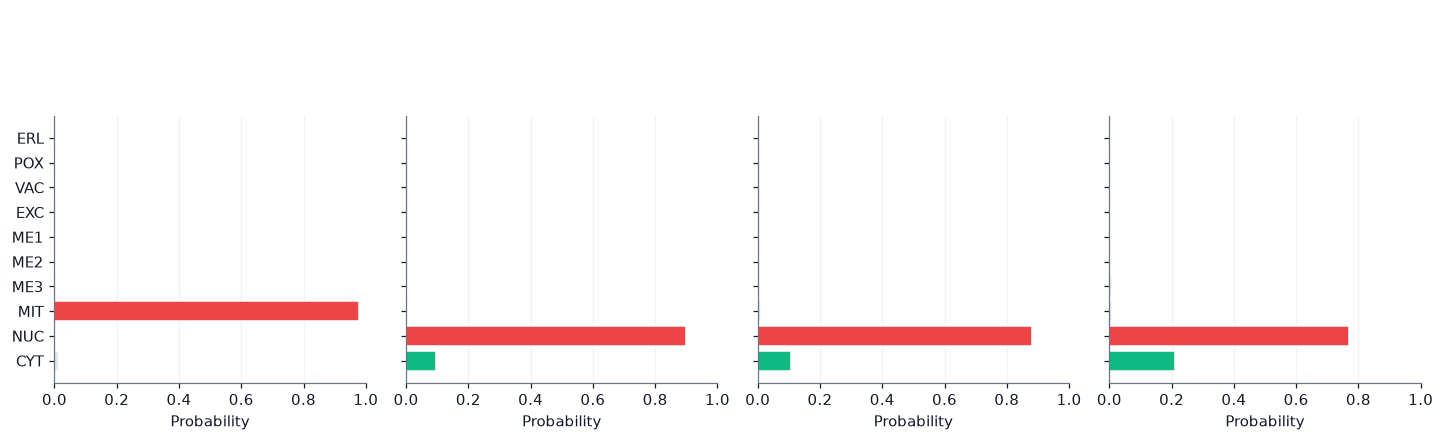

In [37]:
def plot_probability_bars(indices, probs, true_labels, names, title, name):
    """Probability distributions for selected proteins: green = true class, red = predicted (if wrong)."""
    n = len(indices)
    fig, axes = plt.subplots(1, n, figsize=(3.3 * n, 3.8), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, indices):
        predicted = int(np.argmax(probs[i]))
        bar_colors = [COLORS["light"]] * N_CLASSES
        bar_colors[predicted] = COLORS["red"]
        bar_colors[true_labels[i]] = COLORS["green"]
        ax.barh(range(N_CLASSES), probs[i], color=bar_colors, edgecolor="white")
        ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CLASS_ORDER)
        ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
        ax.set_title(f"{names[i]}\ntrue {CLASS_ORDER[true_labels[i]]} | pred {CLASS_ORDER[predicted]}", fontsize=9.5)
        ax.set_xlabel("Probability")
    fig.suptitle(title, fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.04)
    finish(fig, name)

if len(order) > 0:
    plot_probability_bars(order[:4], test_probs, y_test, names_test,
                          "The most confident mistakes (green = true class, red = predicted class)", "19_confident_errors")

Confident mistakes typically involve classes that are biologically close or whose features overlap (soluble proteins, membrane variants). Note also that softmax probabilities are **not guaranteed to be calibrated**: a predicted probability of 0.9 does not automatically mean the prediction is right 90% of the time. Calibration analysis is beyond this notebook but is important whenever probabilities are used for decisions.

## 18. What can and cannot be concluded

**What the results can support.** If your model beats the trivial baselines by a clear margin (on macro-F1 and MCC, not only accuracy), it shows that a small MLP can extract localization information from eight sequence-derived scores, and you can check whether its confusions are biologically plausible.

**What the results do not support.**

1. *Rare-class performance.* Classes with 5–50 proteins have 1–7 validation or test examples. Their per-class metrics are anecdotal.
2. *Generalization to other proteins.* The score features were computed by other programs and summarize only specific signals. Related (homologous) proteins can appear in both training and test partitions; the dataset provides no sequences from which we could build homology-aware splits.
3. *Duplicates.* Some identical feature vectors occur more than once; if copies fall into different partitions, test results are slightly optimistic.
4. *One split, one run.* Model choices were made on a single validation set and a single random initialization.
5. *Other organisms or modern methods.* This is a classical, small benchmark. State-of-the-art localization predictors use protein language models and far larger datasets. Our goal here is to learn the workflow and the mathematics, not to build a predictor for research use.

## 19. Saving the model with its metadata

A model file alone does not document how to use it. We save the class order, feature order, selection decision, split sizes, hyperparameters, test metrics, and package versions next to the model.

In [38]:
model_path = os.path.join(ARTIFACT_DIR, "yeast_localization_mlp.keras")
selected_model.save(model_path)

metadata = {
    "dataset": "UCI Yeast (Nakai, 1991), CC BY 4.0",
    "class_order": CLASS_ORDER,
    "feature_order": FEATURES,
    "selected_model": selected_name,
    "class_weights_used": class_weight_dict if selected_name == "Class-weighted MLP" else None,
    "split_sizes": {"train": int(len(y_train)), "validation": int(len(y_val)), "test": int(len(y_test))},
    "seed": SEED,
    "architecture": {"hidden_units": [32, 16], "activation": "relu", "output": "softmax"},
    "optimizer": {"name": "Adam", "learning_rate": 1e-3},
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "test_metric_95ci": {"accuracy": [float(acc_low), float(acc_high)], "macro_f1": [float(f1_low), float(f1_high)]},
    "versions": {"python": sys.version.split()[0], "keras": keras.__version__,
                 "backend": keras.backend.backend(), "numpy": np.__version__},
}
with open(os.path.join(ARTIFACT_DIR, "yeast_localization_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# Reload and verify that predictions are unchanged.
reloaded = keras.models.load_model(model_path)
print("Reloaded predictions identical:", np.allclose(reloaded.predict(X_test[:20], verbose=0), test_probs[:20], atol=1e-5))

# Using the model on a new protein: raw features go in; preprocessing is part of the model.
new_protein = X_test[:1]
probabilities = reloaded.predict(new_protein, verbose=0)[0]
top3 = np.argsort(-probabilities)[:3]
print("\nTop-3 predicted localizations for one protein:")
for k in top3:
    print(f"  {CLASS_ORDER[k]:>3} ({CLASS_DESCRIPTIONS[CLASS_ORDER[k]]}): {probabilities[k]:.3f}")

Reloaded predictions identical: True

Top-3 predicted localizations for one protein:
  ME2 (Membrane, uncleaved signal): 0.198
  MIT (Mitochondria): 0.192
  EXC (Extracellular): 0.178


## 20. What did we learn?

1. Multiclass classification means estimating $P(y = k \mid x)$; **softmax** turns logits into a valid distribution, is shift-invariant, and has Jacobian $\operatorname{diag}(p) - pp^{\top}$.
2. **Categorical cross-entropy** is the negative log-likelihood of the true labels; for one-hot targets it equals the KL divergence to the target. Its reference values are $\ln K$ and the entropy of the class frequencies.
3. The gradient of softmax + cross-entropy with respect to the logits is $p - y$. Backpropagation extends it layer by layer, and a **gradient check** verifies an implementation.
4. **One-hot** and **integer** targets are equivalent representations with matching losses.
5. On imbalanced data, **accuracy is not enough**: use the confusion matrix, per-class precision/recall/F1, macro-F1, balanced accuracy, and MCC.
6. **Class weights** trade precision for recall on rare classes; softened weights avoid overfitting a handful of samples.
7. Model selection rules should be **declared before** the test evaluation, and the test set is used **once**.
8. A **bootstrap interval** shows how uncertain a test metric is, especially for rare classes.
9. Good results on a small, old benchmark are not biological evidence; limitations must be stated.

### Key terms

| Term | Meaning |
|---|---|
| Logit | Raw output of the last layer, before softmax |
| Softmax | Maps logits to a probability distribution |
| Cross-entropy | $-\sum_k y_k \ln p_k$; negative log-likelihood of the labels |
| KL divergence | Non-negative measure of how one distribution differs from another |
| One-hot encoding | Class $c$ represented as a vector with a single 1 at position $c$ |
| Confusion matrix | Counts of (true class, predicted class) pairs |
| Precision / Recall | Fraction of predictions that are correct / fraction of true cases found |
| Macro-F1 | Unweighted mean of per-class F1 scores |
| MCC | Correlation-type summary of a confusion matrix |
| Class weight | Per-class multiplier of the loss |
| Bootstrap | Resampling method to estimate the uncertainty of a statistic |

## 21. Exercises

### A. Mathematics

1. Show that $\operatorname{softmax}(z)$ is unchanged if a constant is added to all logits, and explain why this means the last Dense layer has "redundant" parameters.
2. Compute by hand the softmax of $z = (1, 2, 3)$ and the cross-entropy if the true class is the third one. Verify with the NumPy functions.
3. Derive $\partial \ell / \partial z_j = p_j - y_j$ yourself, starting from $\ell = -\ln p_c$ with $p = \operatorname{softmax}(z)$.
4. For $K = 2$, show that the categorical cross-entropy with softmax equals the binary cross-entropy with a sigmoid of $z_1 - z_2$.
5. A model predicts the true class with probability $0.5$ for every sample. What is its cross-entropy? What does it mean in terms of the geometric mean of the true-class probability?
6. Show that micro-averaged precision and recall are both equal to accuracy for single-label multiclass classification.
7. A class has precision 0.8 and recall 0.2. Compute its F1-score. Why is F1 closer to the lower of the two numbers than the arithmetic mean would be?
8. With sample weights $w_{c_i}$, write the gradient of the weighted loss with respect to the logits of sample $i$ (Section 15) and explain what happens when $w_{c_i} = 0$.

### B. Programming

1. Run the gradient check with a different architecture (e.g. `[8, 7, 6, 3]`) and with the sigmoid activation in place of ReLU in the first hidden layer (you will need to change both `mlp_forward` and `mlp_backward`).
2. Remove the `Normalization` layer and retrain the baseline. How do the learning curves and macro-F1 change?
3. Train the baseline with five different seeds and plot the distribution of validation macro-F1. How large is the seed-to-seed variation compared with the baseline-vs-weighted difference?
4. Try $\alpha = 0$, $0.25$, $0.5$, $0.75$, and $1$ for the class weights. Plot validation macro-F1 against $\alpha$ together with the recall of the rarest class.
5. Replace one-hot targets and `categorical_crossentropy` by integer labels and `sparse_categorical_crossentropy`. Confirm that the learning curves are equivalent.
6. Compute the **Matthews correlation coefficient** for the test predictions with the function from Section 12 and compare it with accuracy and macro-F1. Which metric is the most pessimistic?
7. Add a Dropout layer between the two hidden layers (`keras.layers.Dropout(0.3)`). Compare the gap between training and validation loss.

### C. Research thinking

1. Suppose a biologist wants to find new peroxisomal proteins. Which metric would you prioritize, precision or recall of `POX`, and why? How would you pick the decision threshold?
2. Describe a split of a protein dataset that avoids homology leakage. What information would you need?
3. Why is it problematic to choose between the two models using the test set, even if only once and "just to check"?

## 22. Further exploration and references

### Dataset

- Nakai, K. (1991). *Yeast* [Dataset]. UCI Machine Learning Repository. <https://doi.org/10.24432/C5KG68> (licence: CC BY 4.0).
- Nakai, K. and Kanehisa, M. (1992). A knowledge base for predicting protein localization sites in eukaryotic cells. *Genomics*, 14, 897–911.

### Keras documentation

- [Losses: probabilistic losses](https://keras.io/api/losses/probabilistic_losses/)
- [Metrics: accuracy metrics](https://keras.io/api/metrics/accuracy_metrics/)
- [Training with built-in methods, including `class_weight`](https://keras.io/guides/training_with_built_in_methods/)
- [Writing your own callbacks](https://keras.io/guides/writing_your_own_callbacks/)
- [`to_categorical`](https://keras.io/api/utils/python_utils/#to_categorical-function)

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 3 (probability and information theory; softmax, cross-entropy, KL divergence), chapter 6 (feed-forward networks and backpropagation), and chapter 5 (maximum likelihood).
- Chollet — *Deep Learning with Python*: the chapters on classification examples and the machine-learning workflow.
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: chapters on neural networks with Keras and on classification metrics.
- Efron and Tibshirani — *An Introduction to the Bootstrap* (for the resampling idea used in Section 16.1).

---

## Next notebook

**05 — Neural Network Regression with Biological Data**

We switch from predicting a *class* to predicting a *continuous value*: estimating the age of abalone from physical measurements. We will compare regression and classification, study MSE, MAE, and Huber losses mathematically, examine feature scaling, and diagnose underfitting and overfitting.